# 08 · CardioTwin what-if simulator: a personalised, explainable digital-twin sandbox

**What it does.** Pick a real held-out test patient (or the clearly labelled synthetic demo patient), see their measurements
and both models' outputs, then change one input or a whole scenario and see, side by side:

* the baseline and hypothetical risk and LOW / MODERATE / HIGH tier of **both saved models** (phone + watch model, ICU reference model),
* **which explanations changed** (exact SHAP deltas, and a bridge from the baseline risk to the scenario risk),
* **how sure the model is** about the change (50 bootstrap refits), whether the edit pushes the model **outside its training range**,
  and whether the model's response **goes against usual clinical direction**,
* several scenarios compared at once, one-way **sensitivity curves**, a **tornado** ranking, a **two-lever response surface**,
* **counterfactuals**: the smallest changes, moving only toward usual target ranges, that bring the risk below a tier cut-off,
* an hour-by-hour **digital-twin timeline** where edited raw watch readings are pushed through the engine's own feature code.

**What is reused (nothing is retrained).** The notebook 05 model bundles (fitted imputer, scaler, model and calibrator), feature schema
and operating points; notebook 06's SHAP method and patient explanation records; notebook 07's risk-policy config, training reference,
SHAP background, bootstrap refits, integrity manifest, input validator and feature builder (which reuse `twin_preprocess.py`).

**How to read every result.** *Hypothetical model simulation.* It shows how this model's output responds to edited inputs. It does
not change the patient's record, does not predict the effect of any treatment and is not medical advice. The models were trained on
ICU stays of 59 patients (MIMIC-IV demo), their tier cut-offs are provisional, and SHAP values are attributions, not causes.

The code lives in `whatif_twin/` next to this notebook (`levers.py`, `scenario.py`, `simulator.py`, `readings_twin.py`, `viz.py`,
`export.py`, `widgets.py`); tests are in `tests/`.

## 0 · Setup

In [1]:
import json, sys, platform, subprocess, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

HERE = next(p for p in (Path.cwd(), Path.cwd() / "what_if_simulator", Path.cwd().parent / "what_if_simulator") if (p / "whatif_twin").exists())
sys.path.insert(0, str(HERE))
import whatif_twin
from whatif_twin import load_simulator, Scenario, Change, viz
from whatif_twin.export import result_payload, simulate_request, save_json, PAYLOAD_FIELDS, PermissionDenied
from whatif_twin.levers import plausible_range

CH, RES = HERE.parent / "charts" / "what_if", HERE.parent / "results" / "what_if"
PAY = RES / "payloads"
for d in (CH, RES, PAY):
    d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)

def show(fig, name):
    fig.savefig(CH / f"{name}.png", bbox_inches="tight", facecolor=viz.SURFACE, dpi=140)
    plt.close(fig)
    display(Image(str(CH / f"{name}.png")))

t0 = time.time()
sim = load_simulator()            # finds the project folder, checks integrity, loads both models once
P = sim.art.paths
print(f"loaded in {time.time() - t0:.1f} s | project root: {P.root} ({P.layout} layout)")
print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", __import__("sklearn").__version__, "| lightgbm", __import__("lightgbm").__version__,
      "| shap", __import__("shap").__version__, "| whatif_twin", whatif_twin.__version__)

loaded in 2.1 s | project root: /mnt/attach/project-files (split layout)
python 3.13.16 | pandas 2.2.3 | numpy 2.5.3 | scikit-learn 1.9.1 | lightgbm 4.7.0 | shap 0.54.1 | whatif_twin 1.0.0


## 1 · Repository assessment: what the simulator stands on

Every artifact is read from the files notebooks 05-07 saved. The checks below prove that the simulator reproduces the saved
risks exactly before anything is simulated.

In [2]:
W, F = sim.models["watch"], sim.models["full"]
assess = {
    "deployed model (phone + watch)": f"{W.bundle['name']} {W.bundle['version']}: {W.bundle['model_type']}, {len(W.features)} inputs, calibration '{W.calibration}'",
    "reference model (hospital data)": f"{F.bundle['name']}: {F.bundle['model_type']}, {len(F.features)} inputs, calibration '{F.calibration}'",
    "prediction target": W.bundle["label_definition"],
    "operating points (provisional)": f"watch MODERATE >= {W.thresholds['moderate']}, HIGH >= {W.thresholds['high']}; ICU MODERATE >= {F.thresholds['moderate']}, HIGH >= {F.thresholds['high']}",
    "SHAP": "watch: exact closed-form linear SHAP (risk_engine.shap_service, training-hour background); ICU: TreeSHAP",
    "model variance": f"{len(W.ensemble)} patient-level bootstrap refits of the watch model (notebook 07)",
    "feature code for raw readings": "risk_engine.input_validator + feature_builder (reuse twin_preprocess.py)",
    "full risk engine (emergency rules, SAR)": "available" if sim.art.full_engine_available else
        "not importable here (needs twin_rules.py); reused modules imported directly",
    "patients": f"{len(sim.patients.ids(False))} held-out test stays (notebook 06 snapshot of every model input at each stay's last test hour)"
                + (" + every test hour from model_final.csv" if sim.patients.test_table is not None else "")
                + " + 1 synthetic demo patient",
}
for k, v in assess.items():
    print(f"{k:42s} {v}")
print("\nintegrity:", json.dumps(sim.art.integrity))

rows = []
for cid in sim.patients.ids(include_synthetic=False):
    c = sim.patients.get(cid)
    for m, saved in c.meta["saved_risk"].items():
        pred = sim.models[m].predict(c.values)
        phi, base = sim.models[m].shap(c.values)
        rows.append({"case": cid, "model": m, "saved_risk": saved, "simulator_risk": pred["prob"],
                     "abs_diff": abs(pred["prob"] - saved), "shap_additivity_error": abs(base + phi.sum() - pred["raw_log_odds"])})
check = pd.DataFrame(rows)
print(f"\nreproduces the saved risks of {check.case.nunique()} stays x 2 models: max |difference| = {check.abs_diff.max():.1e} "
      f"(rounding in the saved CSV); max SHAP additivity error = {check.shap_additivity_error.max():.1e}")
save_json({"assessment": assess, "integrity": sim.art.integrity, "max_abs_diff_vs_saved": check.abs_diff.max(),
           "max_shap_additivity_error": check.shap_additivity_error.max()}, RES / "repository_assessment.json")
check.groupby("model")[["abs_diff", "shap_additivity_error"]].max()

deployed model (phone + watch)             cardiotwin-watch-24h 1.0.0+2026-10-18: Logistic regression (baseline), 46 inputs, calibration 'none'
reference model (hospital data)            cardiotwin-full-24h: LightGBM (Optuna), 40 inputs, calibration 'sigmoid'
prediction target                          first vasopressor start, lactate >= 4 or in-hospital death in (t, t+24h], t = end of the hour bin
operating points (provisional)             watch MODERATE >= 0.0362, HIGH >= 0.0759; ICU MODERATE >= 0.0472, HIGH >= 0.0891
SHAP                                       watch: exact closed-form linear SHAP (risk_engine.shap_service, training-hour background); ICU: TreeSHAP
model variance                             50 patient-level bootstrap refits of the watch model (notebook 07)
feature code for raw readings              risk_engine.input_validator + feature_builder (reuse twin_preprocess.py)
full risk engine (emergency rules, SAR)    not importable here (needs twin_rules.py); reused modules 


reproduces the saved risks of 19 stays x 2 models: max |difference| = 5.1e-05 (rounding in the saved CSV); max SHAP additivity error = 1.8e-14


,abs_diff,shap_additivity_error
model,,
full,0.000046,1.776357e-14
watch,0.000051,4.440892e-16


**Result:** the simulator reproduces the risks notebook 05 saved for all 19 test stays with both models (largest difference
0.00005, which is rounding in the saved CSV), the watch model file matches the SHA-256 recorded by notebook 07, and SHAP values add
up to every output (error below 1e-13). Nothing had to be retrained.

## 2 · What can be changed, and what cannot

A **lever** is a real-world quantity that maps onto one or more model inputs. Moving a lever updates *every* input derived from it
with the training definitions (for example, heart rate also moves the 6-hour mean and maximum, the change over 6 hours, the change vs
the patient's own normal, the shock index and the NEWS2 heart-rate points). Inputs that cannot be recomputed from a single hour
(such as the 24-hour heart-rate SD) are **held** and reported. Section 10 measures how close this is to a full rebuild from raw readings.

Vital-sign edits apply to the **last 6 hourly bins** by default (the same window as the engine's own what-if), or to the
**whole history** (`mode="persistent"`).

In [3]:
levers = sim.lever_table()
levers.to_csv(RES / "levers.csv", index=False)
display(levers[["lever", "label", "unit", "category", "models", "accepted_range", "training_range_99%",
                "counterfactual_candidate", "held_constant"]])
print("Asked about but NOT simulated (no model input exists, so any effect would be invented):")
display(sim.unsupported_table())

,lever,label,unit,category,models,accepted_range,training_range_99%,counterfactual_candidate,held_constant
0,heart_rate,Heart rate,bpm,physiological_signal,"watch, full",20-250,52-128.5,True,"hr_sd_24h, ecg_hr_bpm"
1,spo2,Oxygen saturation,%,physiological_signal,"watch, full",50-100,89-100,True,
2,resp_rate,Breathing rate,/min,physiological_signal,"watch, full",4-60,8-35,True,rr_night_minus_day_24h
3,rhythm_sinus,Normal sinus rhythm,0/1,physiological_signal,watch,0-1,0-1,False,tachy_burden_24h
4,temperature,Temperature,°C,physiological_signal,full,30-43,None,False,
5,inpatient_sbp,Systolic BP (bedside),mmHg,physiological_signal,full,50-250,None,False,
6,weight,Body weight,kg,lifestyle,"watch, full",25-300,39.92-128.5,True,
7,bmi,BMI,kg/m²,lifestyle,"watch, full",12-70,17.4-45.2,False,
8,smoker,Smoking,0/1,lifestyle,"watch, full",0-1,0-1,True,
9,total_chol,Total cholesterol,mg/dL,clinical_lab,"watch, full",50-500,97-257,True,


Asked about but NOT simulated (no model input exists, so any effect would be invented):


,quantity,why it cannot be simulated
0,sleep_duration,"Sleep: no sleep data existed in training (MIMIC-IV ICU stays), so neither mo..."
1,steps,Steps / physical activity: no activity data in training; no model input.
2,physical_activity,Physical activity: no activity data in training; no model input.
3,stress,Stress: no stress or mood input in either model.
4,watch_hrv,Watch heart-rate variability (RMSSD/SDNN from the watch): not measured in tr...
5,diet,Diet / sodium intake: no dietary input in either model.
6,alcohol,"Alcohol: only enters the HAS-BLED score, which is stored as a finished score..."
7,medication_adherence,Medication adherence: no adherence input in either model.
8,watch_blood_pressure,Cuffless watch blood pressure: not an input of the deployed phone + watch mo...
9,glucose_cgm,Continuous glucose: no CGM data; the ICU model only sees the change between ...


## 3 · Choose a patient

The held-out test stays are real, de-identified MIMIC-IV demo patients (open-access PhysioNet demo data) never seen in training.
The synthetic demonstration patient is generated from synthetic watch readings and labelled as synthetic everywhere.

In [4]:
rows = []
for cid in sim.patients.ids():
    c = sim.patients.get(cid)
    r = {"case_id": cid, "source": "SYNTHETIC" if c.is_synthetic else "test split", "hour": c.hour}
    for m in ("watch", "full"):
        if m in c.models:
            p = sim.models[m].predict(c.values)
            r[f"{m}_risk"], r[f"{m}_tier"] = p["prob"], p["tier"]
    r["event_within_24h (technical view)"] = c.meta.get("event_within_24h")
    rows.append(r)
roster = pd.DataFrame(rows)
roster.to_csv(RES / "patient_roster.csv", index=False)
display(roster.style.format({"watch_risk": "{:.1%}", "full_risk": "{:.1%}"}, na_rep="-"))

CASE_ID = "stay-31248398"           # change this to explore another patient (or "synthetic-demo")
case = sim.patients.get(CASE_ID)
print(f"Selected: {case.label} | {case.source} | hour {case.hour}")

,case_id,source,hour,watch_risk,watch_tier,full_risk,full_tier,event_within_24h (technical view)
0,stay-30876334,test split,2120-01-31 17:00:00,2.3%,LOW,0.9%,LOW,0.000000
1,stay-31248398,test split,2201-07-10 10:00:00,10.4%,HIGH,18.3%,HIGH,0.000000
2,stay-31316840,test split,2135-01-13 09:00:00,8.1%,HIGH,20.6%,HIGH,1.000000
3,stay-32145159,test split,2150-06-04 20:00:00,5.2%,MODERATE,2.5%,LOW,0.000000
4,stay-32166508,test split,2148-09-15 21:00:00,1.9%,LOW,0.6%,LOW,0.000000
5,stay-32374504,test split,2117-04-14 14:00:00,3.3%,LOW,1.7%,LOW,0.000000
6,stay-32506122,test split,2167-11-09 20:00:00,5.2%,MODERATE,0.3%,LOW,0.000000
7,stay-33083787,test split,2181-10-26 20:00:00,3.7%,MODERATE,0.8%,LOW,0.000000
8,stay-35026312,test split,2150-03-19 01:00:00,3.0%,LOW,6.0%,MODERATE,1.000000
9,stay-36496303,test split,2144-11-02 15:00:00,3.2%,LOW,0.3%,LOW,0.000000


Selected: Test stay 31248398 (patient 10026255) | MIMIC-IV demo, held-out test split (de-identified, open-access PhysioNet demo data) | hour 2201-07-10 10:00:00


## 4 · Baseline: the patient's measurements and both models' outputs

,input,meaning,value,reference_range,vs_reference,training_median,used_by,source
0,hr,current heart rate,127.00000,60-100 bpm,above range,86.000000,watch,watch
1,hr_mean6h,average heart rate over the last 6 h,95.66667,60-100 bpm,in range,86.833333,"watch, full",watch
2,hr_max6h,highest heart rate in the last 6 h,127.00000,60-100 bpm,above range,95.000000,watch,watch
3,hr_vs_baseline,heart rate compared with this patient's own normal,45.00000,None,,-1.000000,watch,watch
4,spo2,current oxygen saturation,91.00000,95-100%,below range,97.000000,watch,watch
5,spo2_min6h,lowest oxygen saturation in the last 6 h,91.00000,95-100%,below range,95.000000,watch,watch
6,rr,current breathing rate,28.00000,12-20 /min,above range,19.000000,watch,watch
7,rr_mean6h,average breathing rate over 6 h,27.16667,12-20 /min,above range,18.916667,"watch, full",watch
8,rhythm_sinus,is in normal sinus rhythm,0.00000,None,,1.000000,watch,watch
9,age_at_admit,age,67.00000,None,,59.000000,"watch, full",phone_profile


Phone + watch model    10.4%  tier HIGH     (2.42x the training base rate, refits 5-95%: 2.4%-24.2%); 0 missing inputs filled by the fitted imputer / native handling
ICU reference model    18.3%  tier HIGH     (4.27x the training base rate); 0 missing inputs filled by the fitted imputer / native handling


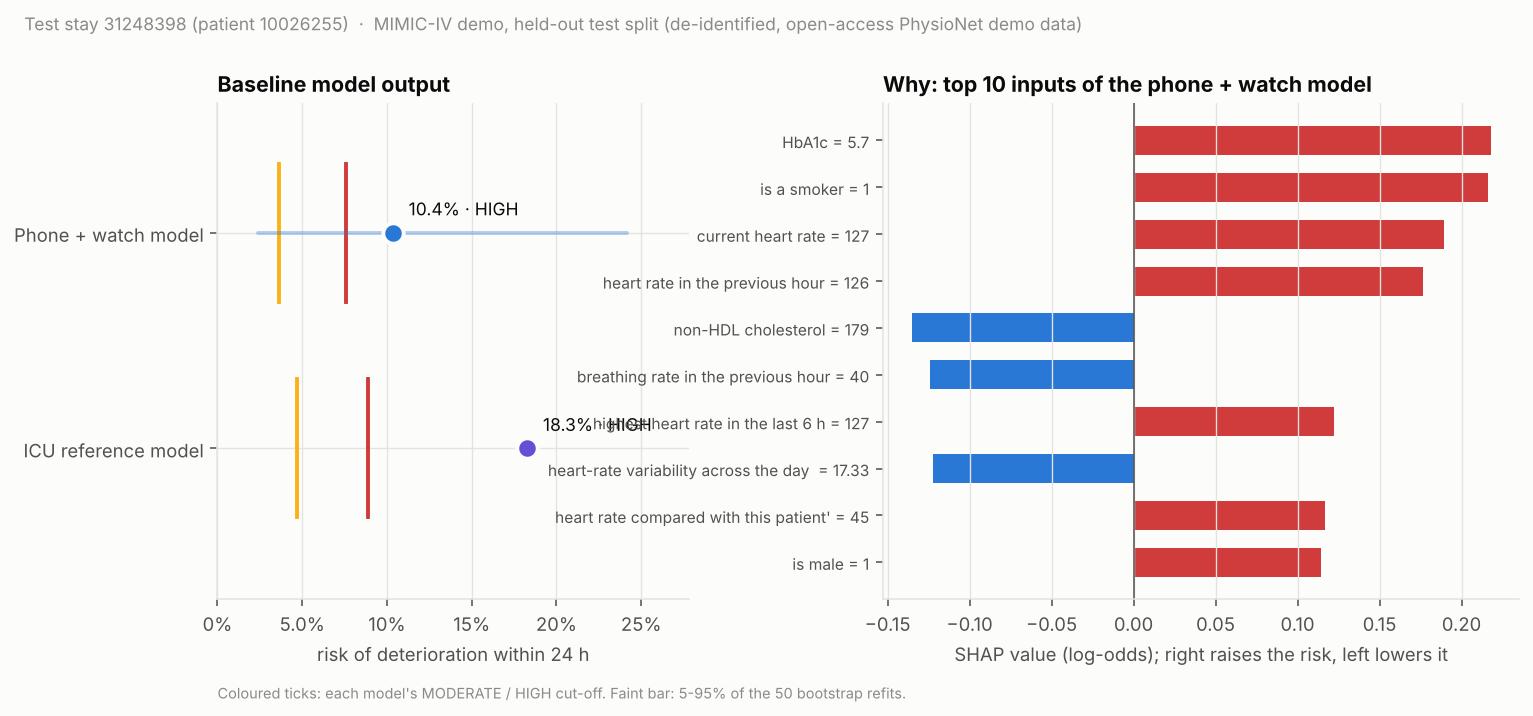

In [5]:
T = sim.art.T
KEY = ["hr", "hr_mean6h", "hr_max6h", "hr_vs_baseline", "spo2", "spo2_min6h", "rr", "rr_mean6h", "rhythm_sinus",
       "age_at_admit", "gender_male", "bmi", "weight_lbs", "smoker", "ascvd_10y_risk", "hba1c", "ldl", "total_chol", "egfr",
       "sbp_outpatient", "n_active_drugs", "shock_index", "map_min6h", "temp_c", "gcs_total", "lab_potassium"]
meas = []
for f in KEY:
    v = case.values.get(f)
    ref = T.REF.get(f, (None,))[0]
    meas.append({"input": f, "meaning": T.TXT.get(f, (f,))[0], "value": v, "reference_range": ref,
                 "vs_reference": T.ref_flag(f, v) if v == v else "missing (model fills the training median)",
                 "training_median": sim.art.median(f),
                 "used_by": ", ".join(m for m in ("watch", "full") if f in sim.models[m].features) or "(context)",
                 "source": W.sources.get(f) or F.sources.get(f)})
display(pd.DataFrame(meas))

base = sim.baseline(case)
for m, b in base.items():
    u = f", refits 5-95%: {b['p05']:.1%}-{b['p95']:.1%}" if "p05" in b else ""
    print(f"{viz.MODEL_NAME[m]:22s} {b['prob']:.1%}  tier {b['tier']:8s} ({b['times_base_rate']}x the training base rate{u}); "
          f"{len(b['missing_inputs'])} missing inputs filled by the fitted imputer / native handling")
show(viz.plot_baseline(sim, case, base), "01_baseline")

## 5 · Change one input: heart rate 15 bpm lower over the last 6 hours

Every model input that changed is listed with its original and hypothetical value, so the scenario is fully traceable.

HYPOTHETICAL MODEL SIMULATION. It shows how this model's output responds to edited inputs. It does not change the patient's record, does not predict the effect of any treatment and is not medical advice. 

Heart rate -15 bpm (last 6 h): watch: 10.4% -> 7.7% (-2.6 points, tier unchanged) | full: 18.3% -> 3.8% (-14.5 points, tier HIGH -> LOW)


,feature,original,simulated,was_missing
0,hr_mean6h,95.66667,80.666670,False
1,hr_lag1,126.00000,111.000000,False
2,hr_delta6h,55.00000,40.000000,False
3,hr_max6h,127.00000,112.000000,False
4,hr,127.00000,112.000000,False
5,hr_trend_24h,0.66667,-14.333330,False
6,hr_vs_baseline,45.00000,30.000000,False
7,news_score_min6h,2.00000,1.000000,False
8,shock_index_lag1,1.04100,0.917071,False
9,shock_index_mean6h,0.75567,0.637185,False


held constant: ['hr_sd_24h', 'ecg_hr_bpm'] | notes: ['NEWS2 hr points re-banded at the 6 h average (-1); approximation for the ICU reference model.']


,scenario,model,affected,baseline_prob,scenario_prob,delta,relative_%,baseline_tier,scenario_tier,tier_change,delta_p05,delta_p95,refits_same_direction_%,robustness,n_ood_inputs,direction_warning
0,Heart rate -15 bpm (last 6 h),watch,True,0.103589,0.077439,-0.026150,-25.244138,HIGH,HIGH,unchanged,-0.067036,-0.003166,100.0,direction consistent across refits,0,False
1,Heart rate -15 bpm (last 6 h),full,True,0.182842,0.037525,-0.145317,-79.476856,HIGH,LOW,HIGH -> LOW,NaN,NaN,NaN,no refits for this model (point estimate only),0,False


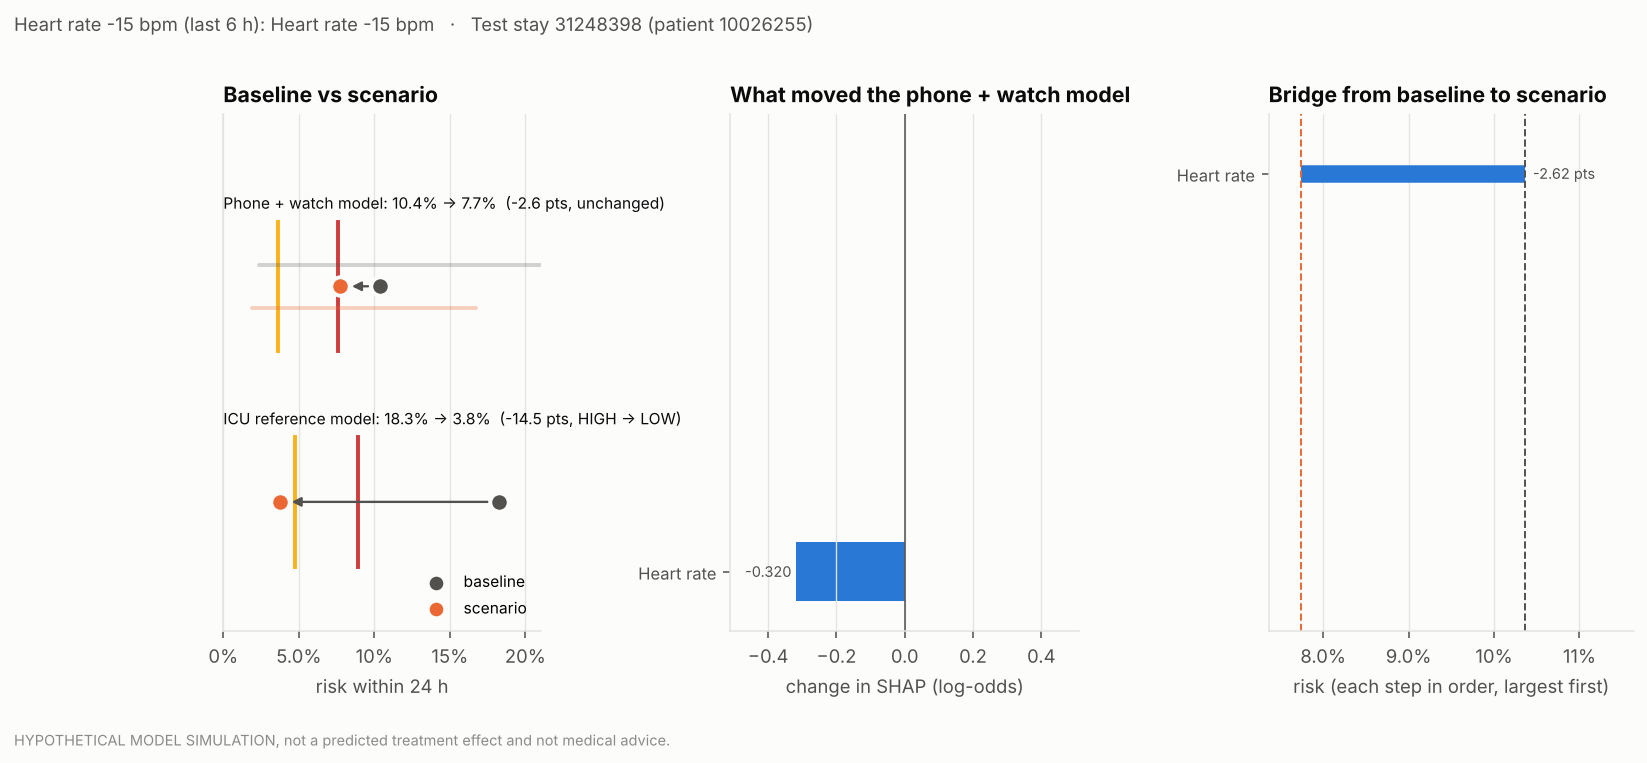

In [6]:
s1 = Scenario.of("Heart rate -15 bpm (last 6 h)", heart_rate={"delta": -15})
r1 = sim.simulate(case, s1)
print(r1.label, "\n")
print(r1.headline())
display(pd.DataFrame(r1.applied.edits))
print("held constant:", r1.applied.held, "| notes:", r1.applied.notes)
display(r1.table())
show(viz.plot_result(sim, r1), "02_single_change")
save_json(result_payload(sim, r1), PAY / "single_change_heart_rate.json")

**Result (stay 31248398):** 15 bpm less over the last 6 hours lowers the phone + watch model from 10.4% to 7.7%; all 50 refits agree on
the direction, but the patient stays HIGH. The ICU reference model drops much further, 18.3% to 3.8% (HIGH to LOW), because heart rate
also enters its shock index and NEWS2 inputs. Its NEWS2 update is an approximation (heart-rate points re-banded at the 6-hour average),
so the ICU number is a coarser estimate than the watch number.

## 6 · Change several inputs together

Two hypothetical scenarios for the same patient: **vital signs back in the usual range** (heart rate 100 bpm, SpO2 95%, breathing rate
20 /min over the last 6 hours) and **longer-term risk factors** (stops smoking, 5 kg lighter, LDL 100 mg/dL). The second scenario
also updates the patient's ASCVD 10-year risk through the pooled cohort equations, re-anchored on the recorded score.

Vitals in usual range: watch: 10.4% -> 8.9% (-1.5 points, tier unchanged) | full: 18.3% -> 3.9% (-14.3 points, tier HIGH -> LOW)
   edits: hr_mean6h 95.67->100, hr_lag1 126->100, spo2_min6h 91->95, hr_delta6h 55->28, rr_lag1 40->20, spo2_mean6h 92.33->95, rr_mean6h 27.17->20, rr_max6h 40->20, rr_delta6h 6->-2, rr_min6h 22->20, hr_max6h 127->100, hr 127->100, spo2_lag1 91->95, spo2_max6h 96->95, hr_trend_24h 0.6667->5, rr_vs_baseline 4->-4, spo2 91->95, hr_vs_baseline 45->18, rr 28->20, news_score_min6h 2->0, shock_index_lag1 1.041->0.8262, shock_index_mean6h 0.7557->0.7899, shock_index 1.134->0.8929, news_score_mean6h 5.333->1.333
   watch: robustness = within model variance (direction not stable); out of training range: none
   full: robustness = no refits for this model (point estimate only); out of training range: none
Risk factors improved: watch: 10.4% -> 7.6% (-2.8 points, tier HIGH -> MODERATE) | full: 18.3% -> 5.5% (-12.8 points, tier HIGH -> MODERATE)
   edits: bmi 25.8->22.17

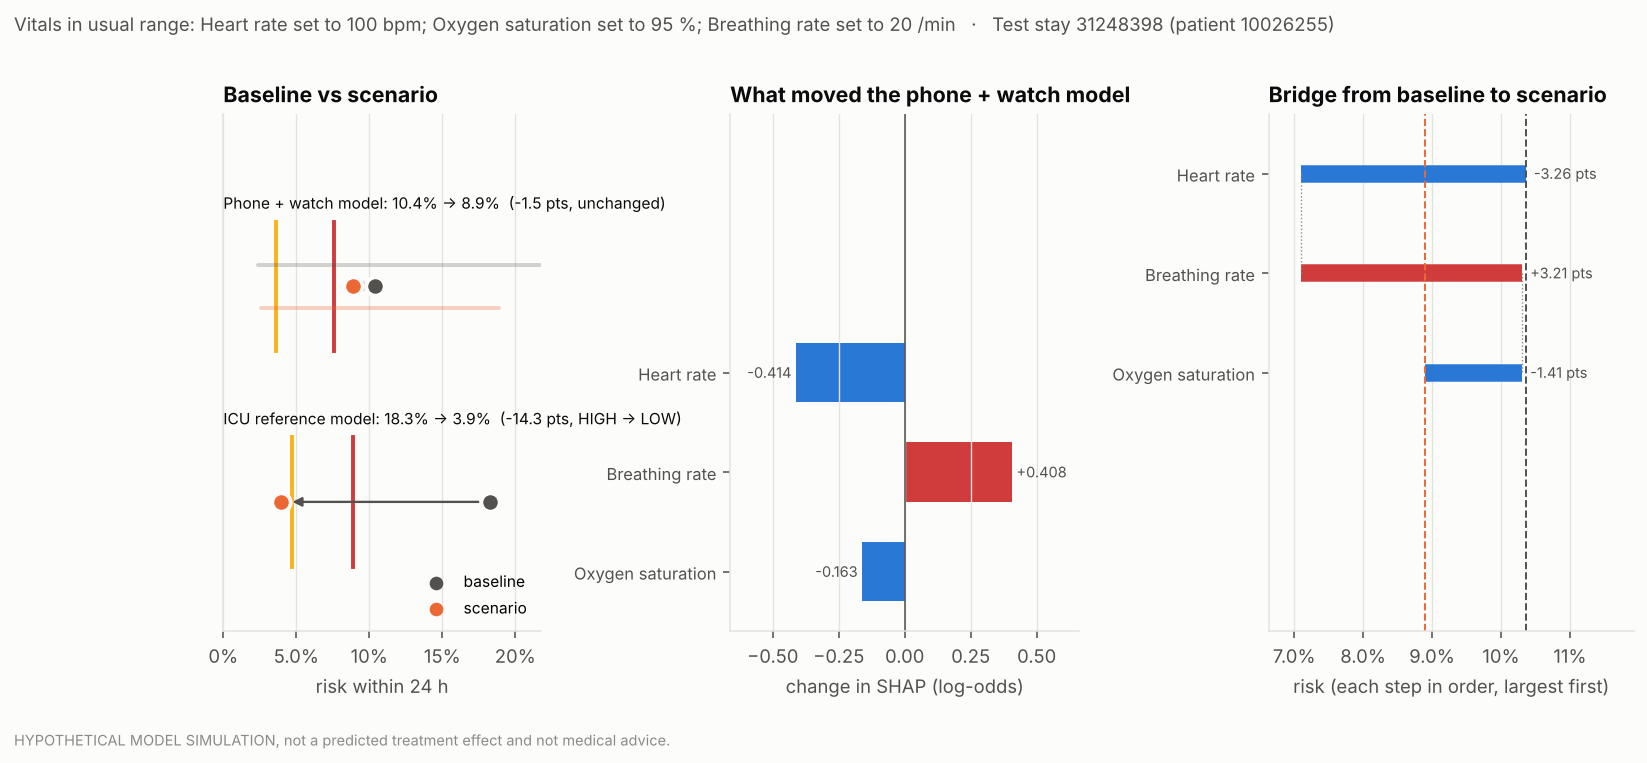

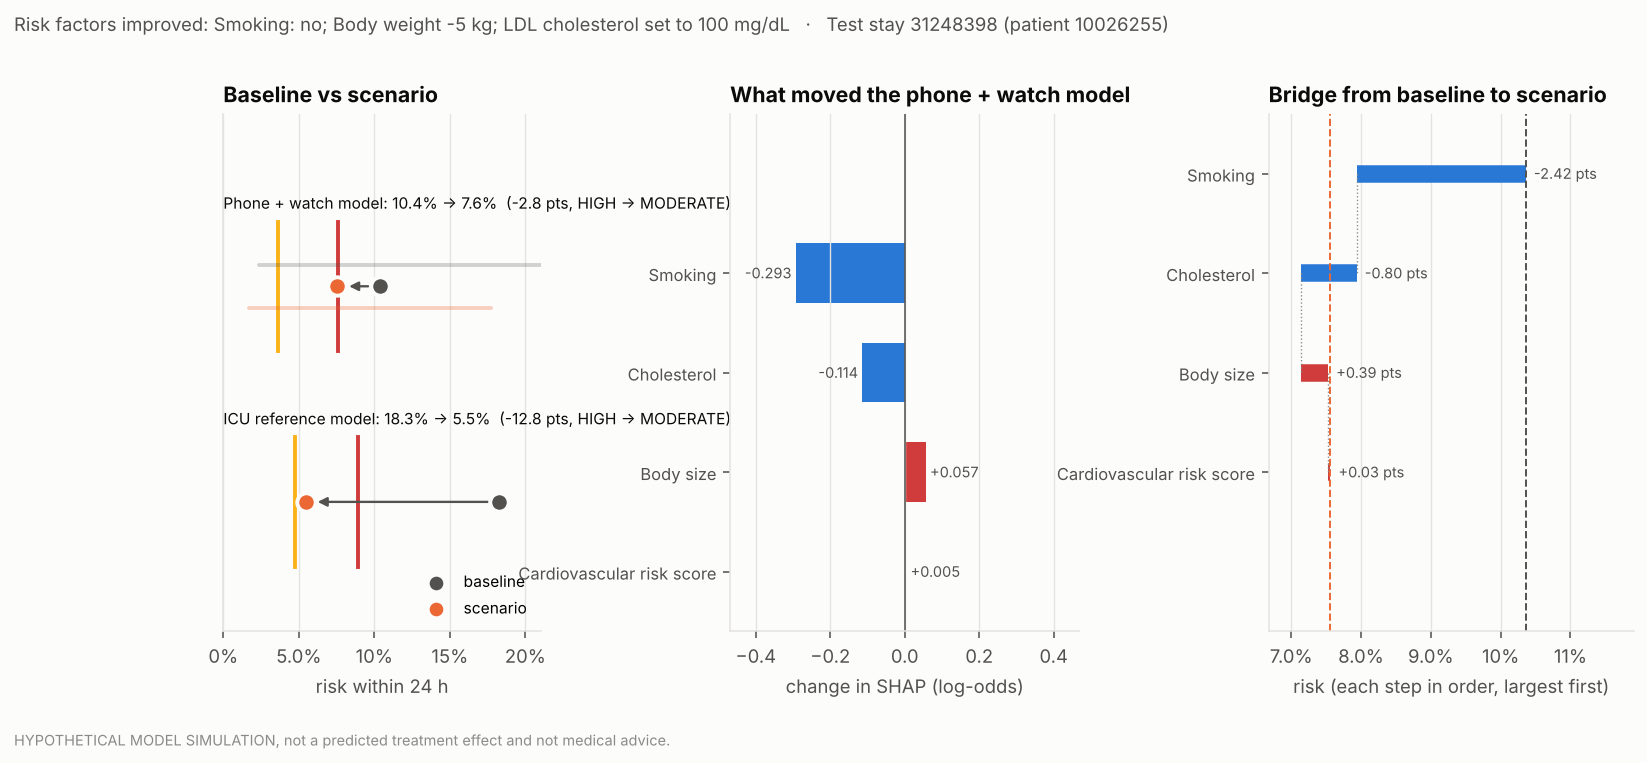

In [7]:
s2 = Scenario.of("Vitals in usual range", heart_rate={"value": 100}, spo2={"value": 95}, resp_rate={"value": 20})
s3 = Scenario.of("Risk factors improved", smoker=0, weight={"delta": -5}, ldl={"value": 100})
r2, r3 = sim.simulate(case, s2), sim.simulate(case, s3)
for r in (r2, r3):
    print(r.headline())
    print("   edits:", ", ".join(f"{e['feature']} {e['original']:.4g}->{e['simulated']:.4g}" if e["original"] is not None
                                 else f"{e['feature']} (missing)->{e['simulated']:.4g}" for e in r.applied.edits))
    for m, o in r.outcomes.items():
        print(f"   {m}: robustness = {o.uncertainty.get('verdict')}; out of training range: {[d['feature'] for d in o.out_of_distribution] or 'none'}")
show(viz.plot_result(sim, r2), "03_multi_change_vitals")
show(viz.plot_result(sim, r3), "04_multi_change_risk_factors")
for r, n in ((r2, "multi_change_vitals"), (r3, "multi_change_risk_factors")):
    save_json(result_payload(sim, r), PAY / f"{n}.json")

**Result:** bringing the vital signs into the usual range lowers the watch model only 1.5 points, and that change is *within model
variance*: the watch model learned that a higher breathing rate lowers risk, so normalising breathing rate pushes the other way
(section 7 shows it). The risk-factor scenario (stops smoking, 5 kg lighter, LDL 100) moves both models from HIGH to MODERATE.

## 7 · Which explanations changed (SHAP)

SHAP values add up exactly to each model's raw log-odds, so the change in SHAP across all inputs equals the change in the model's
output. For the **linear watch model**, only the edited inputs' SHAP values move. For the **tree-based ICU model**, inputs that were
*not* edited can still change their SHAP value because trees model interactions; the table shows how much of the change that is.

In [8]:
for m, o in r2.outcomes.items():
    d = o.shap_delta
    edited = {e["feature"] for e in r2.applied.edits}
    print(f"{viz.MODEL_NAME[m]}: sum of SHAP changes = {d.sum():+.4f} = change in raw log-odds "
          f"{o.scenario['raw_log_odds'] - o.baseline['raw_log_odds']:+.4f}; "
          f"share carried by inputs that were NOT edited (interactions): {d[~d.index.isin(edited)].abs().sum() / d.abs().sum():.0%}")
    g = o.group_delta(T)
    display(g[g.delta.abs() > 1e-6].round(4).head(8))
    top = d.reindex(d.abs().sort_values(ascending=False).index)[:8]
    display(pd.DataFrame({"input": top.index, "meaning": [T.TXT.get(f, (f,))[0] for f in top.index],
                          "original": [case.values.get(f) for f in top.index], "hypothetical": [r2.applied.values.get(f) for f in top.index],
                          "shap_before": o.shap_baseline[top.index].values, "shap_after": o.shap_scenario[top.index].values,
                          "shap_change": top.values, "edited": [f in edited for f in top.index]}).round(4))

Phone + watch model: sum of SHAP changes = -0.1686 = change in raw log-odds -0.1686; share carried by inputs that were NOT edited (interactions): 0%


,baseline,scenario,delta
group,,,
Heart rate,0.4966,0.0830,-0.4136
Breathing rate,-0.4837,-0.0760,0.4077
Oxygen saturation,0.3562,0.1935,-0.1627


,input,meaning,original,hypothetical,shap_before,shap_after,shap_change,edited
0,hr,current heart rate,127.0,100.0,0.1893,0.0622,-0.1271,True
1,rr_max6h,highest breathing rate in the last 6 h,40.0,20.0,-0.1069,0.0178,0.1247,True
2,hr_lag1,heart rate in the previous hour,126.0,100.0,0.1766,0.0573,-0.1192,True
3,rr_lag1,breathing rate in the previous hour,40.0,20.0,-0.1240,-0.0075,0.1165,True
4,hr_max6h,highest heart rate in the last 6 h,127.0,100.0,0.1224,0.0199,-0.1025,True
5,spo2_lag1,oxygen saturation in the previous hour,91.0,95.0,0.1043,0.0311,-0.0732,True
6,hr_vs_baseline,heart rate compared with this patient's own normal,45.0,18.0,0.1165,0.0484,-0.0680,True
7,spo2,current oxygen saturation,91.0,95.0,0.0921,0.0293,-0.0628,True


ICU reference model: sum of SHAP changes = -3.4634 = change in raw log-odds -3.4634; share carried by inputs that were NOT edited (interactions): 35%


,baseline,scenario,delta
group,,,
NEWS2 score,0.4561,-0.6781,-1.1342
Blood pressure and shock index,0.6990,-0.3714,-1.0704
12-lead ECG,1.5783,1.2677,-0.3106
Body size,1.0030,0.6993,-0.3037
Heart rate,0.4979,0.2795,-0.2184
Smoking,1.5886,1.3915,-0.1971
Calcium,0.2591,0.1418,-0.1173
Bleeding risk and medicines,0.2663,0.1788,-0.0875


,input,meaning,original,hypothetical,shap_before,shap_after,shap_change,edited
0,shock_index_lag1,shock index in the previous hour,1.0410,0.8262,0.7305,-0.1369,-0.8674,True
1,news_score_mean6h,average NEWS2 score over 6 h,5.3333,1.3333,0.3450,-0.3157,-0.6607,True
2,news_score_min6h,lowest NEWS2 score in the last 6 h,2.0000,0.0000,0.1111,-0.3623,-0.4735,True
3,r_amp_mv,R-wave amplitude on the ECG,0.3190,0.3190,1.6727,1.3613,-0.3113,False
4,shock_index,shock index (heart rate ÷ systolic BP),1.1340,0.8929,0.3491,0.0645,-0.2846,True
5,hr_lag1,heart rate in the previous hour,126.0000,100.0000,0.2475,0.0320,-0.2155,True
6,smoker,is a smoker,1.0000,1.0000,1.5886,1.3915,-0.1971,False
7,weight_kg,weight,69.0000,69.0000,0.2939,0.1427,-0.1512,False


**Result:** for the watch model the heart-rate and SpO2 groups lower the risk while the breathing-rate group raises it by almost as much,
which is why the combined scenario changes little. For the ICU model the change is led by the NEWS2 and shock-index inputs, and 35% of
it is carried by inputs that were not edited (R-wave amplitude, smoking, weight): the trees let the effect of one input depend on others.

## 8 · Compare several scenarios

A small scenario library, run for the same patient. The orange band is the 5-95% range of the change across the 50 bootstrap
refits of the watch model: where it crosses the baseline, the direction of the change is not stable.

,scenario,model,baseline_prob,scenario_prob,delta,tier_change,refits_same_direction_%,robustness,n_ood_inputs,direction_warning
0,Heart rate -15 bpm (last 6 h),watch,10.4%,7.7%,-2.62%,unchanged,100.000000,direction consistent across refits,0,False
1,Heart rate -15 bpm (last 6 h),full,18.3%,3.8%,-14.53%,HIGH -> LOW,-,no refits for this model (point estimate only),0,False
2,Vitals in usual range,watch,10.4%,8.9%,-1.46%,unchanged,66.000000,within model variance (direction not stable),0,False
3,Vitals in usual range,full,18.3%,3.9%,-14.35%,HIGH -> LOW,-,no refits for this model (point estimate only),0,False
4,Risk factors improved,watch,10.4%,7.6%,-2.80%,HIGH -> MODERATE,100.000000,direction consistent across refits,0,False
5,Risk factors improved,full,18.3%,5.5%,-12.81%,HIGH -> MODERATE,-,no refits for this model (point estimate only),0,False
6,SpO2 to 96% only,watch,10.4%,8.3%,-2.07%,unchanged,88.000000,within model variance (direction not stable),0,False
7,SpO2 to 96% only,full,18.3%,10.1%,-8.22%,unchanged,-,no refits for this model (point estimate only),0,False
8,Breathing rate 18 /min only,watch,10.4%,15.7%,+5.36%,unchanged,90.000000,within model variance (direction not stable),0,True
9,Breathing rate 18 /min only,full,18.3%,10.3%,-7.98%,unchanged,-,no refits for this model (point estimate only),0,False


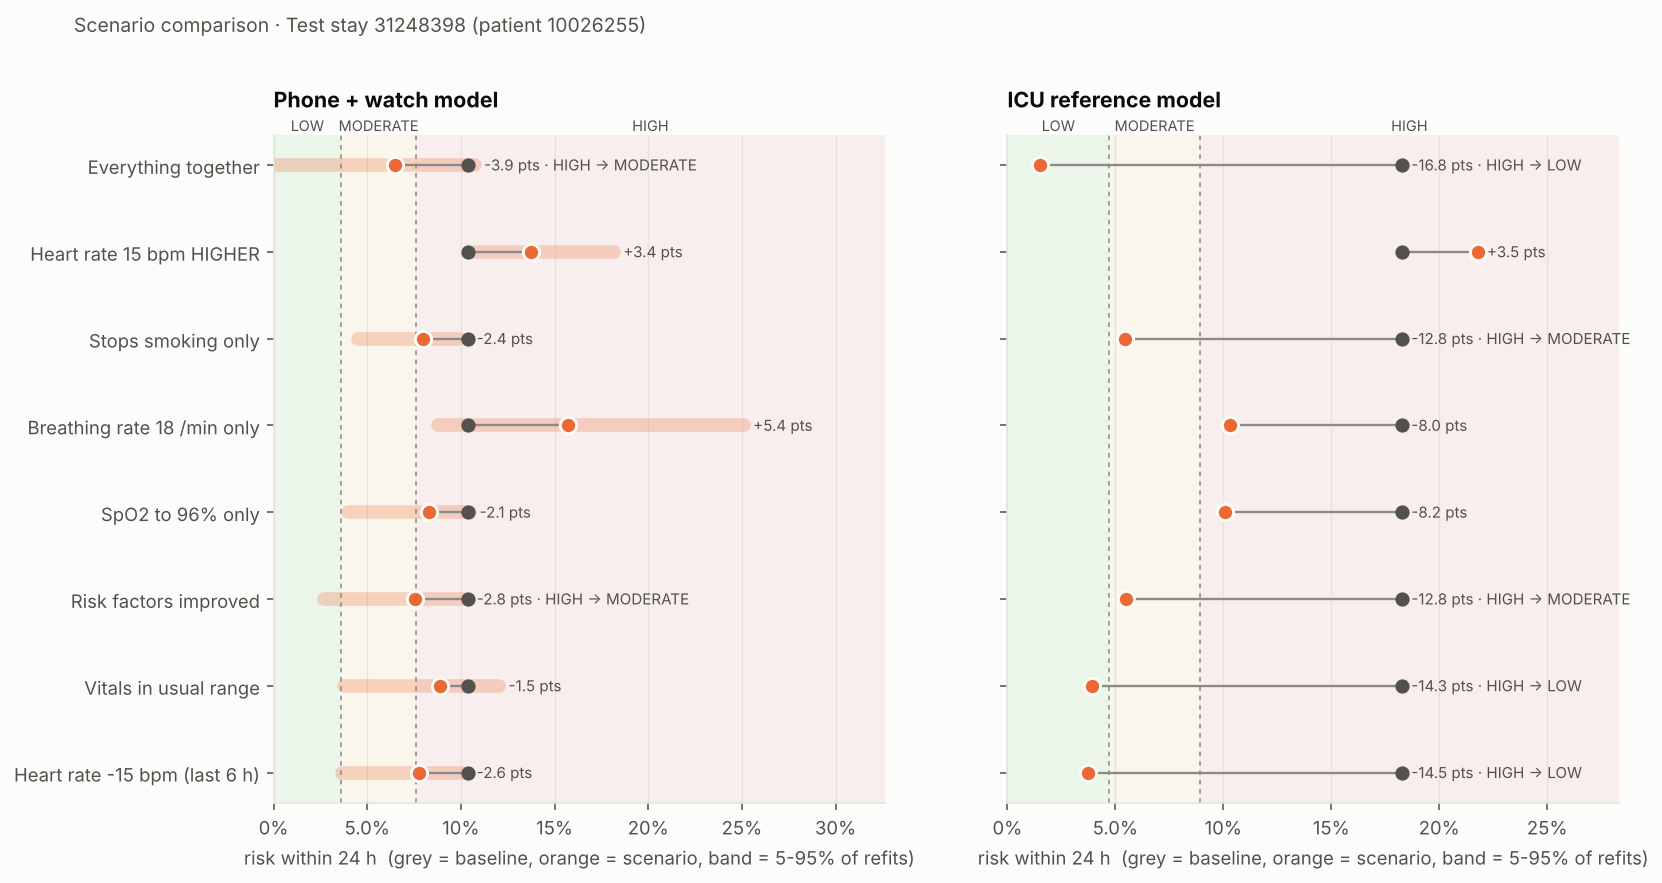

In [9]:
LIBRARY = [
    s1, s2, s3,
    Scenario.of("SpO2 to 96% only", spo2={"value": 96}),
    Scenario.of("Breathing rate 18 /min only", resp_rate={"value": 18}),
    Scenario.of("Stops smoking only", smoker=0),
    Scenario.of("Heart rate 15 bpm HIGHER", heart_rate={"delta": 15}),
    Scenario.of("Everything together", heart_rate={"value": 100}, spo2={"value": 95}, resp_rate={"value": 20}, smoker=0,
                weight={"delta": -5}, ldl={"value": 100}),
]
cmp, cmp_results = sim.compare(case, LIBRARY)
cmp.to_csv(RES / "scenario_comparison.csv", index=False)
display(cmp[["scenario", "model", "baseline_prob", "scenario_prob", "delta", "tier_change", "refits_same_direction_%", "robustness",
             "n_ood_inputs", "direction_warning"]].style.format({"baseline_prob": "{:.1%}", "scenario_prob": "{:.1%}", "delta": "{:+.2%}"}, na_rep="-"))
show(viz.plot_scenarios(sim, cmp, case), "05_scenario_comparison")

## 9 · Explore the response: sensitivity, tornado and a two-lever surface

* **Sensitivity curves** move one lever across its training range with everything else held (an individual conditional expectation
  curve). Grey areas are outside the training range, where the model extrapolates.
* The **tornado** ranks levers by how much one standard step (for example 10 bpm, 3 SpO2 points, quitting smoking) moves the risk.
* The **surface** shows two levers at once with the tier cut-offs as contour lines.

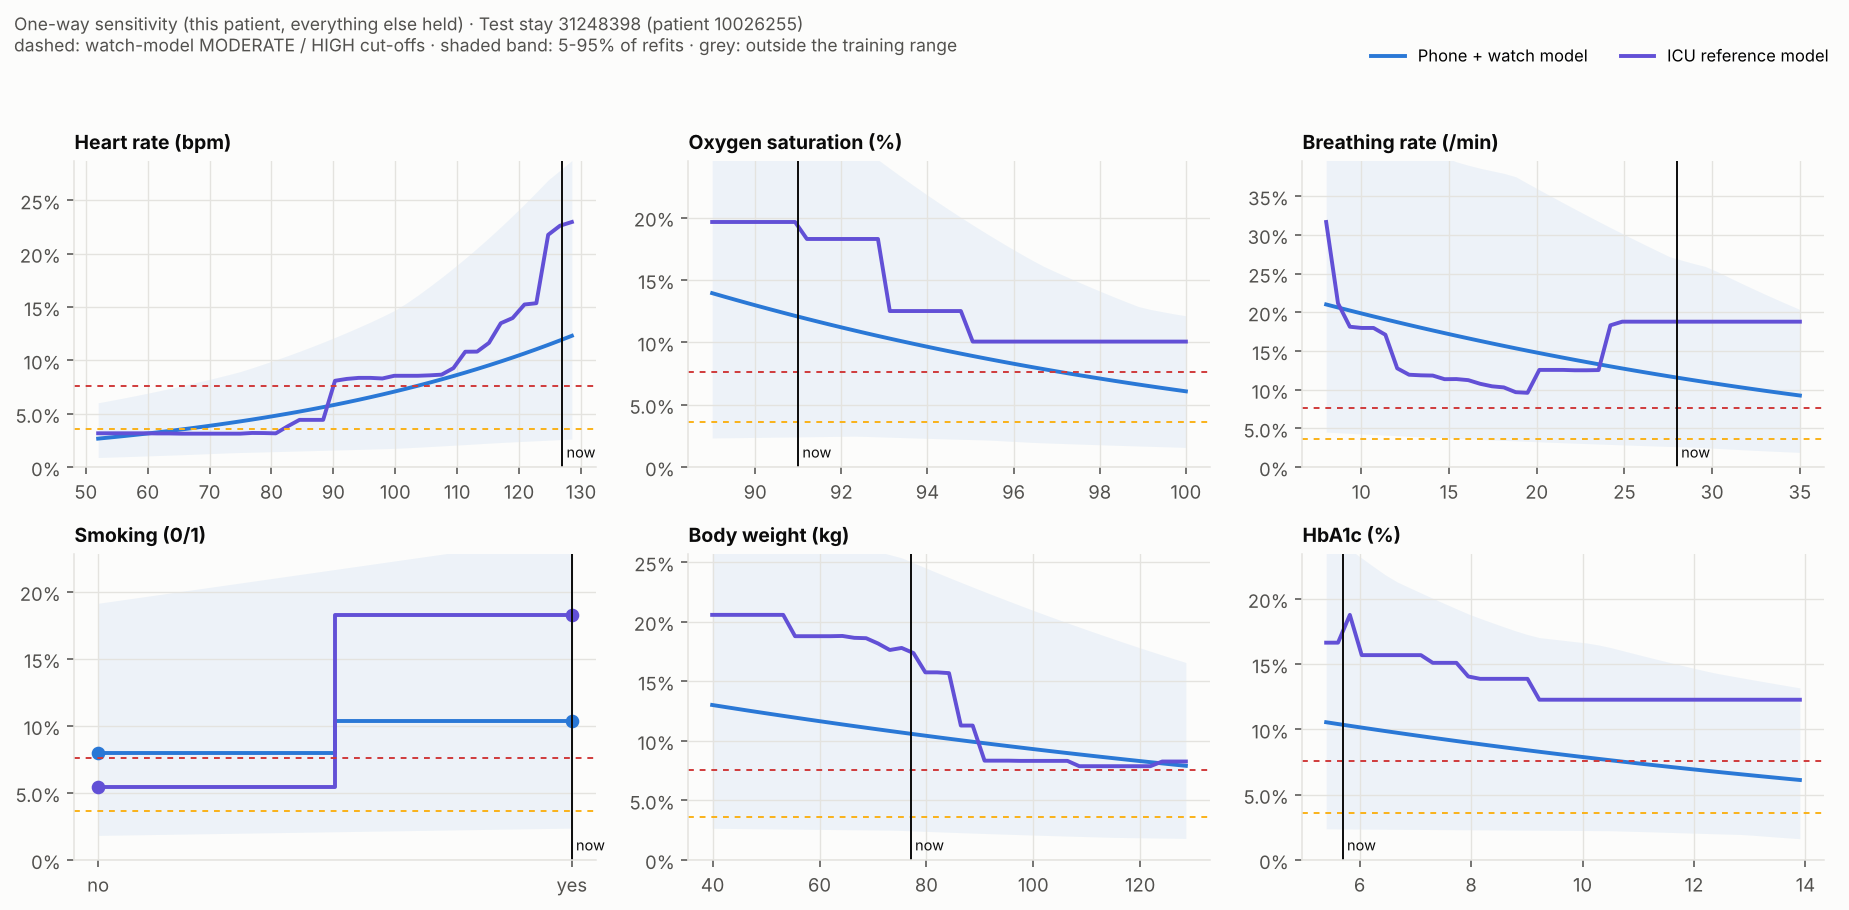

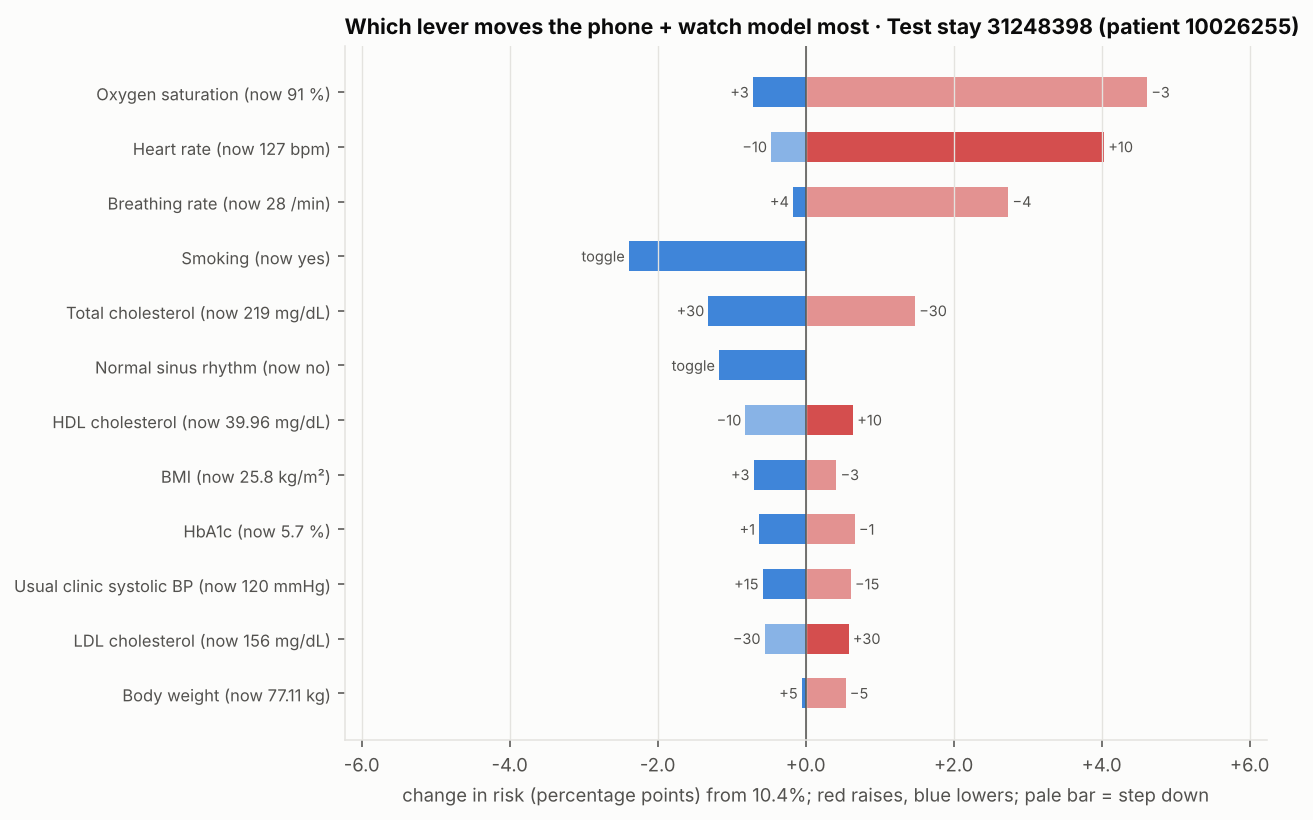

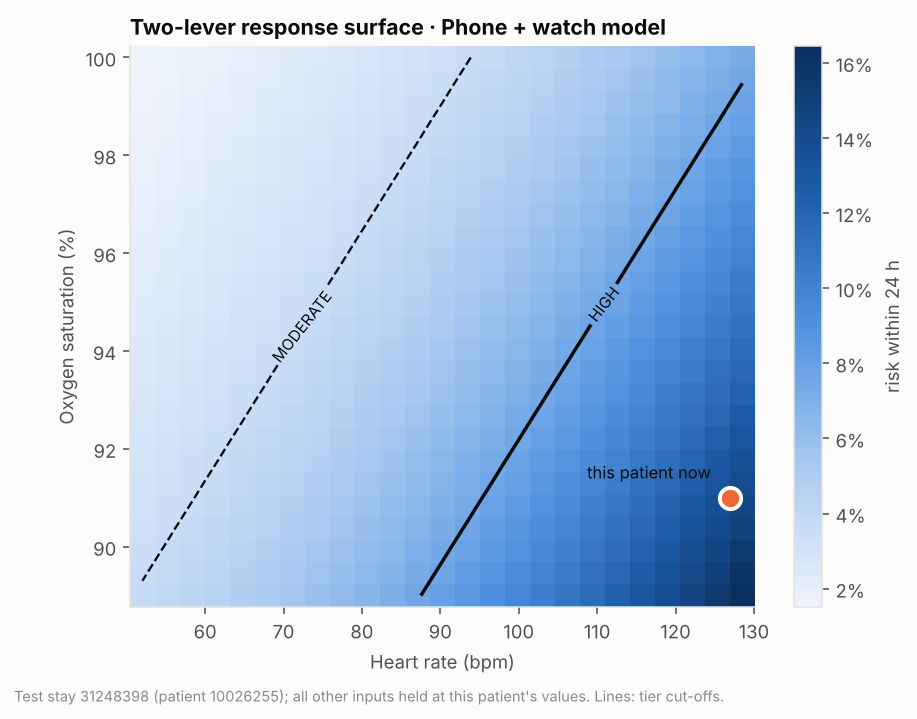

In [10]:
SENS = [k for k in ["heart_rate", "spo2", "resp_rate", "smoker", "weight", "hba1c"] if k in sim.available_levers(case)]
curves = [sim.sensitivity(case, k) for k in SENS]
pd.concat(curves).to_csv(RES / "sensitivity_curves.csv", index=False)
show(viz.plot_sensitivity(sim, curves, case), "06_sensitivity")
tor = sim.tornado(case, "watch")
tor.to_csv(RES / "tornado_watch.csv", index=False)
show(viz.plot_tornado(tor, case, "watch", base["watch"]["prob"]), "07_tornado")
surf = sim.surface(case, "heart_rate", "spo2", "watch")
show(viz.plot_surface(sim, surf, case), "08_surface_hr_spo2")

## 10 · Counterfactuals: the smallest changes that lower the tier

The search tries every single lever and every pair, on a grid that only moves each lever **toward its usual target band and never
past it** (heart rate toward 60-100 bpm, SpO2 toward 95-100%, breathing rate toward 12-20 /min, BMI toward 18.5-24.9, quitting smoking,
LDL toward 70-100 mg/dL, ...), within the training range. Cost is the size of the change in standard steps. Non-modifiable inputs
(age, sex, height) are never proposed. These are **model counterfactuals**: they show what the model responds to, not what a
clinician should do.

target MODERATE: searched 421 scenarios; baseline 10.4%, cut-off 7.6%; reachable: True


,changes,n_changes,cost_steps,prob,delta,tier,reaches_target,note
0,Heart rate 127->100 bpm,1,2.700000,7.1%,-3.26%,MODERATE,True,model counterfactual (not a treatment recommendation)
1,Smoking: no + LDL cholesterol 156->128 mg/dL,2,1.930000,7.6%,-2.80%,MODERATE,True,model counterfactual (not a treatment recommendation)
2,Oxygen saturation 91->94.33 % + Smoking: no,2,2.110000,7.2%,-3.14%,MODERATE,True,model counterfactual (not a treatment recommendation)
3,Heart rate 127->113.5 bpm + Smoking: no,2,2.350000,7.1%,-3.27%,MODERATE,True,model counterfactual (not a treatment recommendation)
4,Heart rate 127->100 bpm + Total cholesterol 219->215.8 mg/dL,2,2.810000,7.2%,-3.16%,MODERATE,True,model counterfactual (not a treatment recommendation)
5,Heart rate 127->104.5 bpm + LDL cholesterol 156->137.3 mg/dL,2,2.870000,7.5%,-2.87%,MODERATE,True,model counterfactual (not a treatment recommendation)
6,Heart rate 127->109 bpm + Oxygen saturation 91->95 %,2,3.130000,7.3%,-3.07%,MODERATE,True,model counterfactual (not a treatment recommendation)


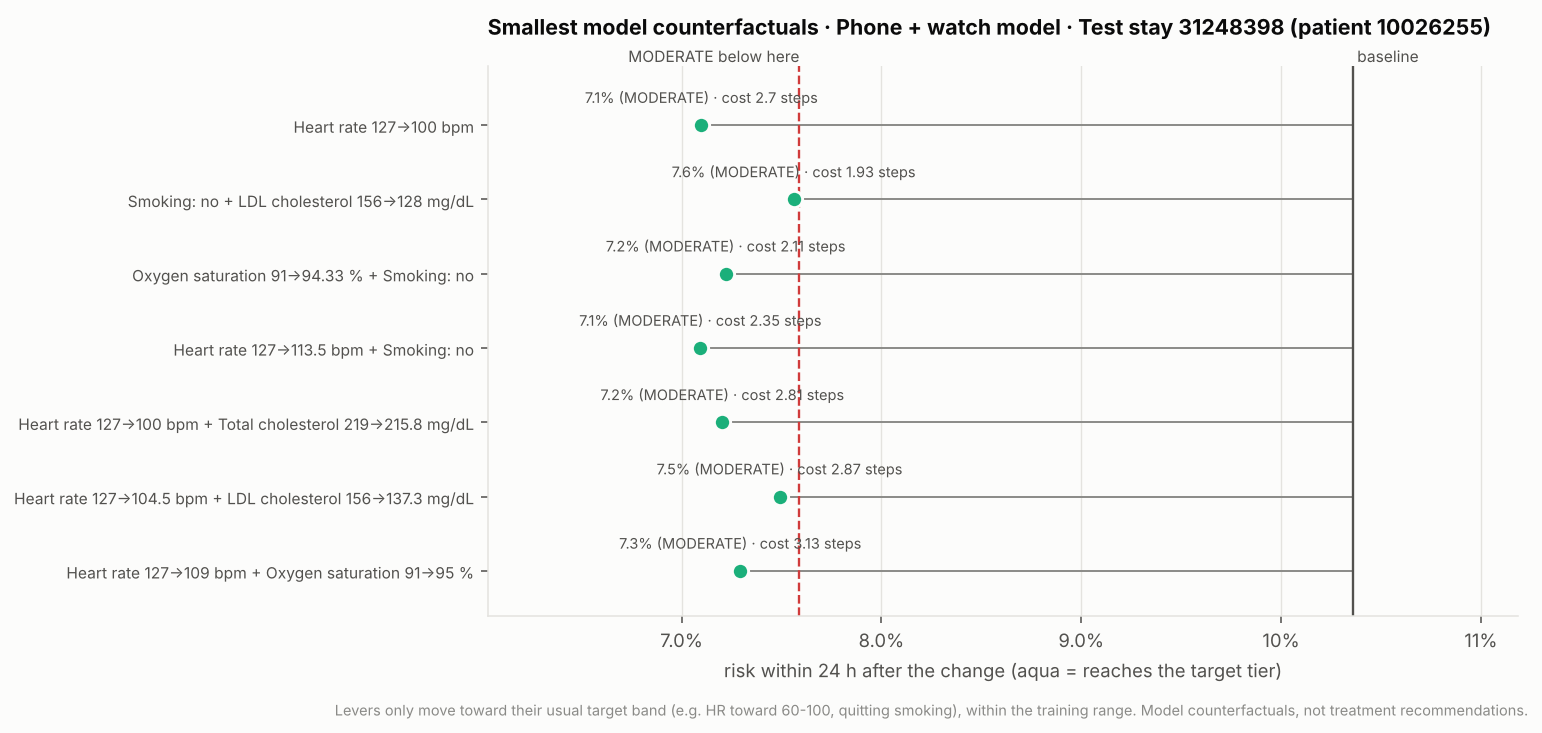

target LOW: searched 421 scenarios; baseline 10.4%, cut-off 3.6%; reachable: False


,changes,n_changes,cost_steps,prob,delta,tier,reaches_target,note
0,Heart rate 127->100 bpm + Smoking: no,2,3.700000,5.4%,-4.94%,MODERATE,False,target not reachable by moving these levers toward their usual target bands; closest options
1,Heart rate 127->100 bpm + Oxygen saturation 91->95 %,2,4.030000,6.1%,-4.26%,MODERATE,False,target not reachable by moving these levers toward their usual target bands; closest options
2,Heart rate 127->100 bpm + LDL cholesterol 156->100 mg/dL,2,4.570000,6.4%,-3.98%,MODERATE,False,target not reachable by moving these levers toward their usual target bands; closest options
3,Oxygen saturation 91->95 % + Smoking: no,2,2.330000,6.9%,-3.50%,MODERATE,False,target not reachable by moving these levers toward their usual target bands; closest options
4,Heart rate 127->100 bpm,1,2.700000,7.1%,-3.26%,MODERATE,False,target not reachable by moving these levers toward their usual target bands; closest options
5,Smoking: no + LDL cholesterol 156->100 mg/dL,2,2.870000,7.2%,-3.19%,MODERATE,False,target not reachable by moving these levers toward their usual target bands; closest options
6,Heart rate 127->100 bpm + Total cholesterol 219->215.8 mg/dL,2,2.810000,7.2%,-3.16%,MODERATE,False,target not reachable by moving these levers toward their usual target bands; closest options
7,Smoking: no,1,1.000000,8.0%,-2.39%,HIGH,False,target not reachable by moving these levers toward their usual target bands; closest options


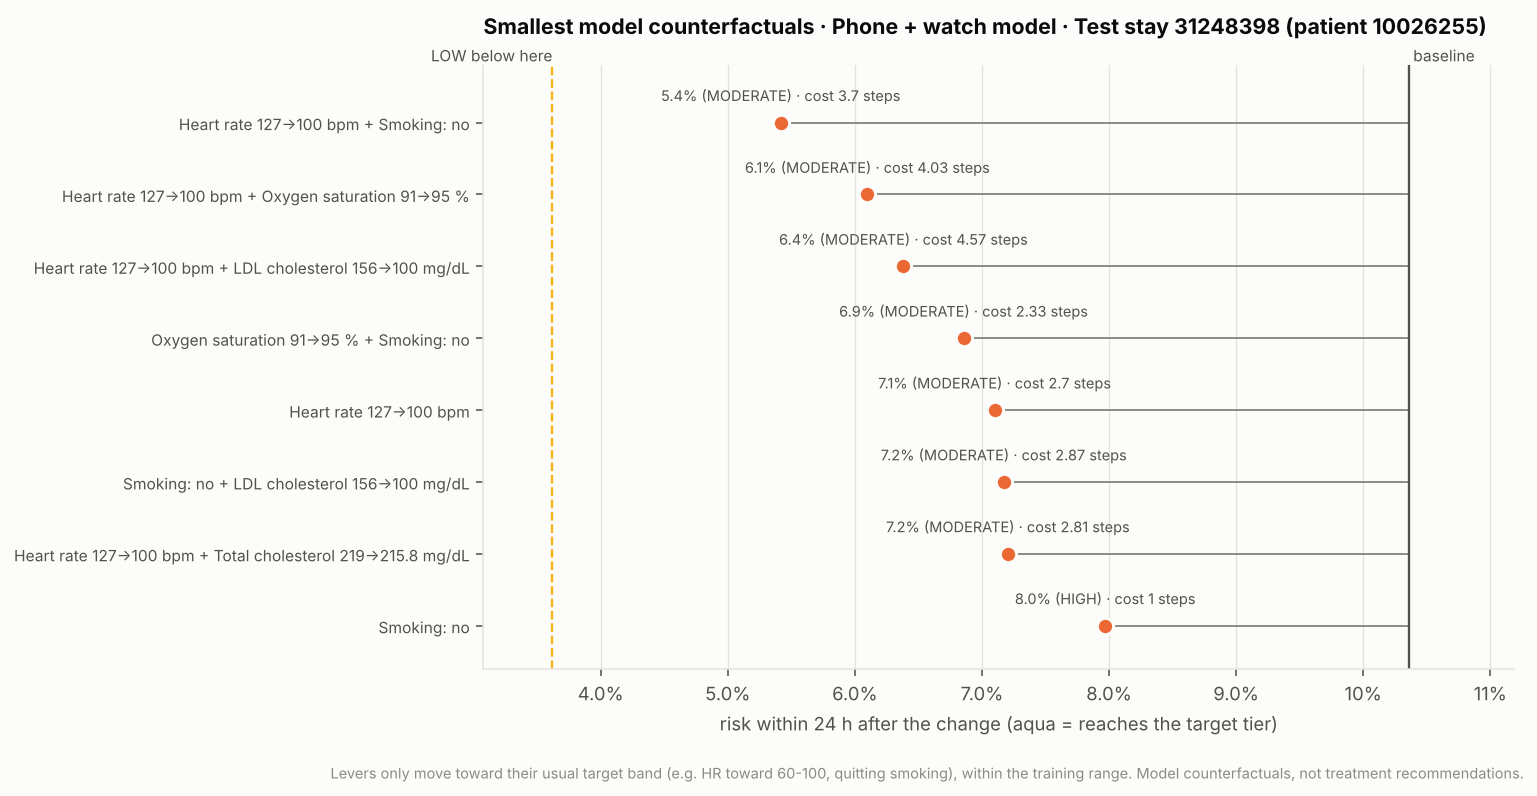

In [11]:
for tgt in ("MODERATE", "LOW"):
    cf = sim.counterfactual(case, model="watch", target_tier=tgt)
    print(f"target {tgt}: searched {cf.attrs.get('searched')} scenarios; baseline {cf.attrs['baseline_prob']:.1%}, "
          f"cut-off {cf.attrs['limit']:.1%}; reachable: {bool(len(cf) and cf.reaches_target.any())}")
    if len(cf):
        display(cf.drop(columns="scenario").style.format({"prob": "{:.1%}", "delta": "{:+.2%}"}))
        cf.drop(columns="scenario").to_csv(RES / f"counterfactuals_watch_{tgt.lower()}.csv", index=False)
        show(viz.plot_counterfactuals(cf, case), f"09_counterfactuals_{tgt.lower()}")

**Result:** for stay 31248398 one change is enough to reach MODERATE in the watch model: heart rate from 127 to 100 bpm (7.1%, below the
7.6% cut-off). Stopping smoking plus a lower LDL also gets there. LOW (below 3.6%) cannot be reached by any one or two levers moved
toward their usual ranges; the closest is heart rate 100 bpm plus stopping smoking (5.4%).

## 11 · How much to trust a simulated change

Three checks are attached to every result:

1. **Model variance**: the same scenario is scored by the 50 bootstrap refits of the watch model. A change is called *consistent* only
   when at least 90% of refits agree on its direction and the 5-95% range of the change excludes zero.
2. **Out-of-distribution**: edited inputs outside the 0.5-99.5 percentile training range are flagged as extrapolation.
3. **Clinical direction**: when a single-lever change moves the risk against the usual clinical direction (for example, a *higher*
   breathing rate *lowering* the risk), the result says so. Such patterns come from 59 training patients and should not be relied on.

The two models are also compared: when they disagree on the direction, the change is model-dependent.

In [12]:
probe = [Scenario.of(f"{lab}", **{k: v}) for lab, k, v in [
    ("HR -10", "heart_rate", {"delta": -10}), ("HR +10", "heart_rate", {"delta": 10}), ("SpO2 +3", "spo2", {"delta": 3}),
    ("RR -6", "resp_rate", {"delta": -6}), ("RR +6", "resp_rate", {"delta": 6}), ("Stops smoking", "smoker", 0),
    ("Weight -10 kg", "weight", {"delta": -10}), ("HR set to 175 (extrapolation)", "heart_rate", {"value": 175}),
    ("HbA1c -1", "hba1c", {"delta": -1})]]
rows = []
for s in probe:
    r = sim.simulate(case, s)
    if r.status == "REJECTED":
        continue
    w, f = r.outcomes["watch"], r.outcomes.get("full")
    rows.append({"scenario": s.name, "watch_delta": w.delta, "refits_same_direction_%": w.uncertainty.get("same_direction_%"),
                 "watch_delta_p05": w.uncertainty.get("delta_p05"), "watch_delta_p95": w.uncertainty.get("delta_p95"),
                 "verdict": w.uncertainty.get("verdict"), "icu_delta": f.delta if f and f.affected else np.nan,
                 "models_agree_on_direction": (np.sign(w.delta) == np.sign(f.delta)) if f and f.affected and abs(f.delta) > 1e-4 else None,
                 "out_of_training_range": ", ".join(d["feature"] for d in w.out_of_distribution) or "",
                 "against_clinical_direction": bool(w.direction_warnings)})
trust = pd.DataFrame(rows)
trust.to_csv(RES / "robustness_checks.csv", index=False)
display(trust.style.format({c: "{:+.2%}" for c in ["watch_delta", "watch_delta_p05", "watch_delta_p95", "icu_delta"]}, na_rep="-"))
for s in probe:
    r = sim.simulate(case, s)
    for m, o in r.outcomes.items():
        for w_ in o.direction_warnings:
            print(f"⚠ {s.name} [{m}]: {w_}")

,scenario,watch_delta,refits_same_direction_%,watch_delta_p05,watch_delta_p95,verdict,icu_delta,models_agree_on_direction,out_of_training_range,against_clinical_direction
0,HR -10,-1.82%,100.000000,-4.68%,-0.22%,direction consistent across refits,-12.38%,True,hr_delta6h,False
1,HR +10,+2.15%,100.000000,+0.24%,+5.13%,direction consistent across refits,+0.89%,True,"hr, hr_delta6h, hr_lag1, hr_vs_baseline",False
2,SpO2 +3,-2.10%,90.000000,-6.41%,+0.13%,within model variance (direction not stable),-8.22%,True,,False
3,RR -6,+2.15%,86.000000,-0.86%,+6.01%,within model variance (direction not stable),-5.22%,False,,True
4,RR +6,-1.82%,86.000000,-4.95%,+0.87%,within model variance (direction not stable),+0.51%,False,"rr_lag1, rr_max6h, rr_mean6h, rr_min6h",True
5,Stops smoking,-2.39%,100.000000,-5.83%,-0.47%,direction consistent across refits,-12.82%,True,,False
6,Weight -10 kg,+0.85%,100.000000,+0.07%,+2.30%,direction consistent across refits,+0.51%,True,,False
7,HR set to 175 (extrapolation),+17.07%,100.000000,+1.60%,+33.52%,direction consistent across refits,+7.56%,True,"hr, hr_delta6h, hr_lag1, hr_max6h, hr_mean6h, hr_trend_24h, hr_vs_baseline",False
8,HbA1c -1,+0.66%,88.000000,-0.03%,+3.32%,within model variance (direction not stable),-1.64%,False,hba1c,False


⚠ RR -6 [watch]: The watch model's response to breathing rate goes against the usual clinical direction. It learned this association from 59 training patients; it is not evidence that the change is harmful or helpful.
⚠ RR +6 [watch]: The watch model's response to breathing rate goes against the usual clinical direction. It learned this association from 59 training patients; it is not evidence that the change is harmful or helpful.


**Result:** heart rate, smoking and weight changes are consistent across refits. SpO2, breathing rate and HbA1c changes are not:
fewer than 90% of refits agree on the direction, and for breathing rate and HbA1c the two models disagree. Breathing-rate responses are
flagged as against the usual clinical direction. Setting heart rate to 175 bpm is flagged as extrapolation: every heart-rate input is
outside the training range, so that number should not be read at all.

## 12 · Reading-level digital twin: edit the raw watch readings, rebuild everything

For the synthetic demonstration patient (48 hours of synthetic watch readings every 15 minutes, with a gradual deterioration over the
last 12 hours) the simulator edits the **raw readings** and rebuilds every model input with the engine's validator and feature builder,
which reuse the training feature code. All derived inputs, including the 24-hour SD and the change vs the patient's own normal, are then
exact, and the risk can be followed **hour by hour**.

SYNTHETIC DEMONSTRATION PATIENT (generated readings; not a real person)
baseline: 7.1% (MODERATE)


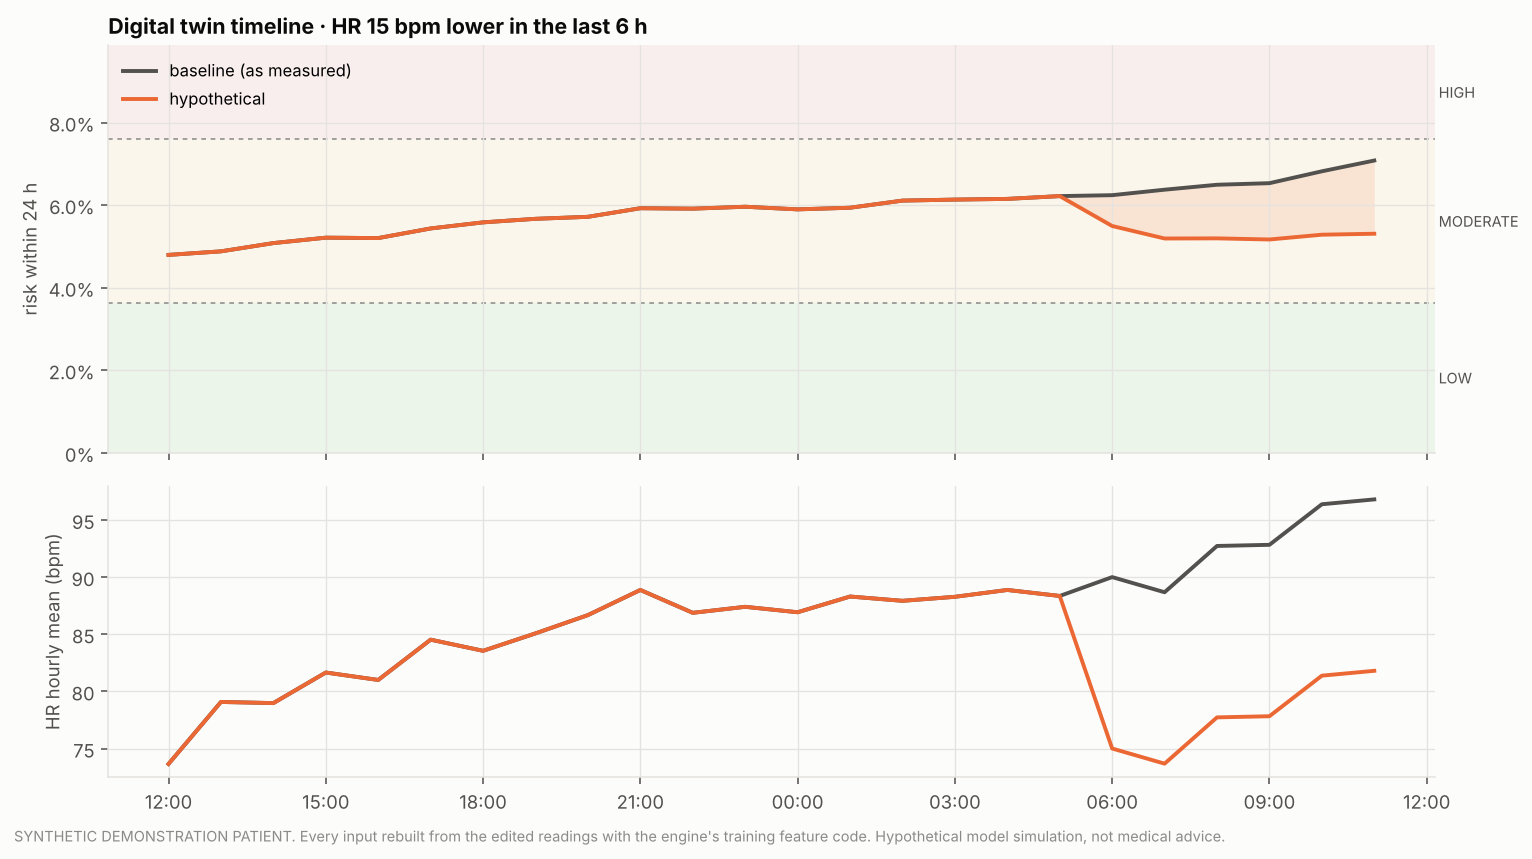

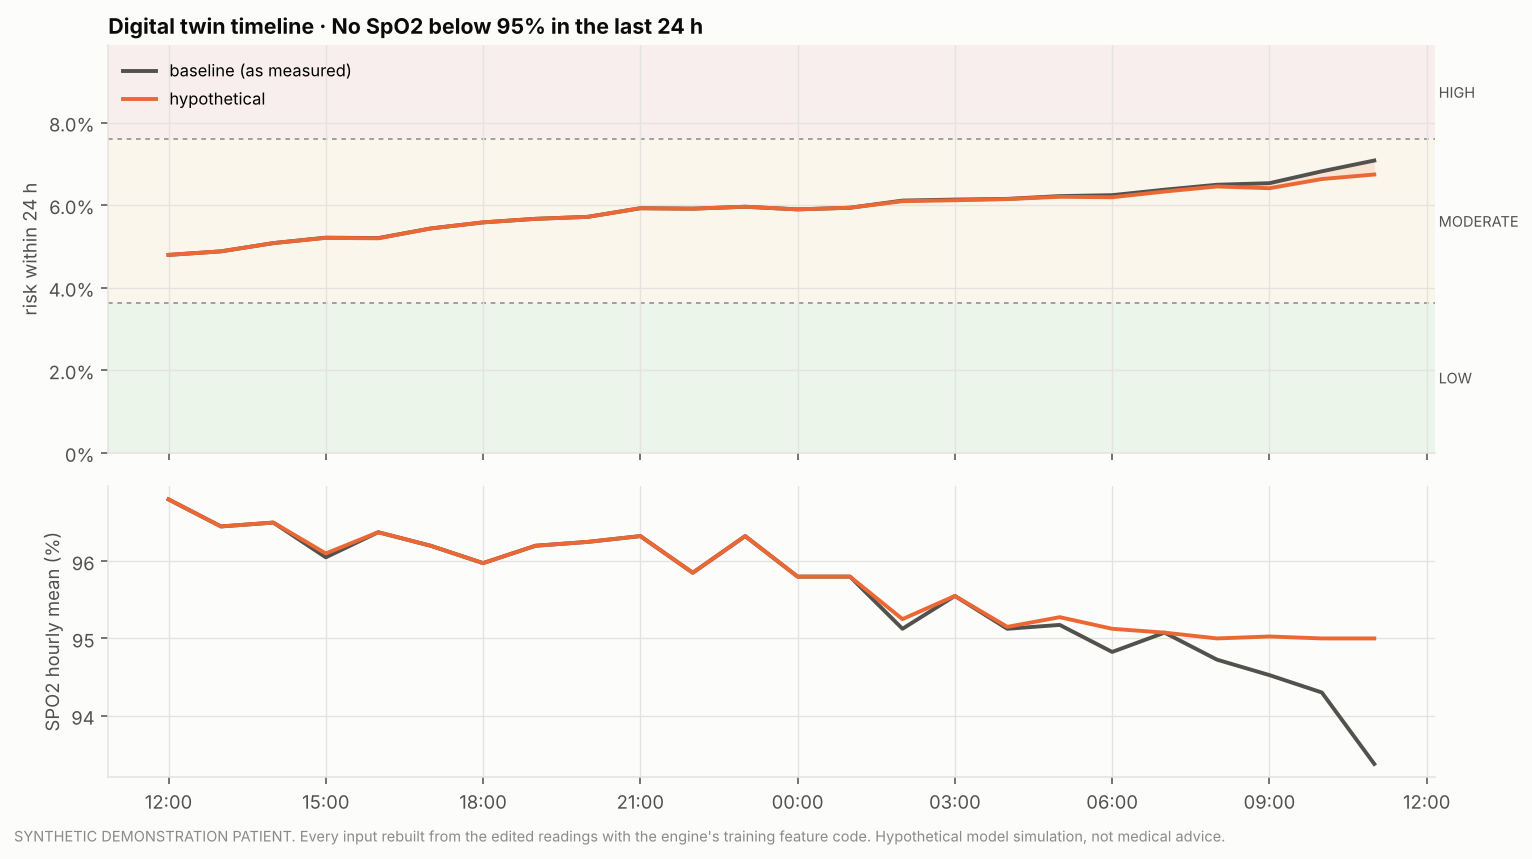

,scenario,baseline,hypothetical,delta,tier,hours_HIGH_baseline_24h,hours_HIGH_hypothetical_24h
0,HR 15 bpm lower in the last 6 h,7.1%,5.3%,-1.77%,MODERATE -> MODERATE,0,0
1,No SpO2 below 95% in the last 24 h,7.1%,6.7%,-0.34%,MODERATE -> MODERATE,0,0
2,Breathing rate 4 /min lower in the last 12 h,7.1%,7.6%,+0.54%,MODERATE -> HIGH,0,1
3,Stops smoking + LDL 100,7.1%,5.0%,-2.08%,MODERATE -> MODERATE,0,0


In [13]:
syn = sim.synthetic_case()
print(syn.source)
print(f"baseline: {sim.models['watch'].predict(syn.values)['prob']:.1%} ({sim.models['watch'].predict(syn.values)['tier']})")
EDITS = {
    "HR 15 bpm lower in the last 6 h": ([{"signal": "hr", "delta": -15, "hours": 6}], "hr"),
    "No SpO2 below 95% in the last 24 h": ([{"signal": "spo2", "floor": 95, "hours": 24}], "spo2"),
    "Breathing rate 4 /min lower in the last 12 h": ([{"signal": "rr", "delta": -4, "hours": 12}], "rr"),
    "Stops smoking + LDL 100": ([{"profile": "smoker", "value": 0}, {"clinical": "ldl", "value": 100}], "hr"),
}
rows = []
for i, (name, (ed, sig)) in enumerate(EDITS.items()):
    out = sim.reading_scenario(syn, ed)
    rows.append({"scenario": name, "baseline": out["baseline"]["prob"], "hypothetical": out["scenario"]["prob"],
                 "delta": out["delta"], "tier": f"{out['baseline']['tier']} -> {out['scenario']['tier']}",
                 "hours_HIGH_baseline_24h": int((out["trajectory_baseline"].tier == "HIGH").sum()),
                 "hours_HIGH_hypothetical_24h": int((out["trajectory_scenario"].tier == "HIGH").sum())})
    if i < 2:
        show(viz.plot_trajectory(out, sim, sig, title=f"Digital twin timeline · {name}"), f"10_twin_timeline_{i + 1}")
twin = pd.DataFrame(rows)
twin.to_csv(RES / "reading_level_scenarios.csv", index=False)
display(twin.style.format({"baseline": "{:.1%}", "hypothetical": "{:.1%}", "delta": "{:+.2%}"}))

### 12b · How good are the feature-level edits? (validation against the full rebuild)

The feature-level simulator (sections 5-11) edits model inputs directly because, for the test patients, only one hour of inputs is
available here. Here the same edits are applied both ways on the synthetic patient and the risks compared.

feature-level vs full rebuild: mean |error| 0.15 points, max 0.86 points over 14 edits (the difference comes from held inputs such as the 24 h SD)


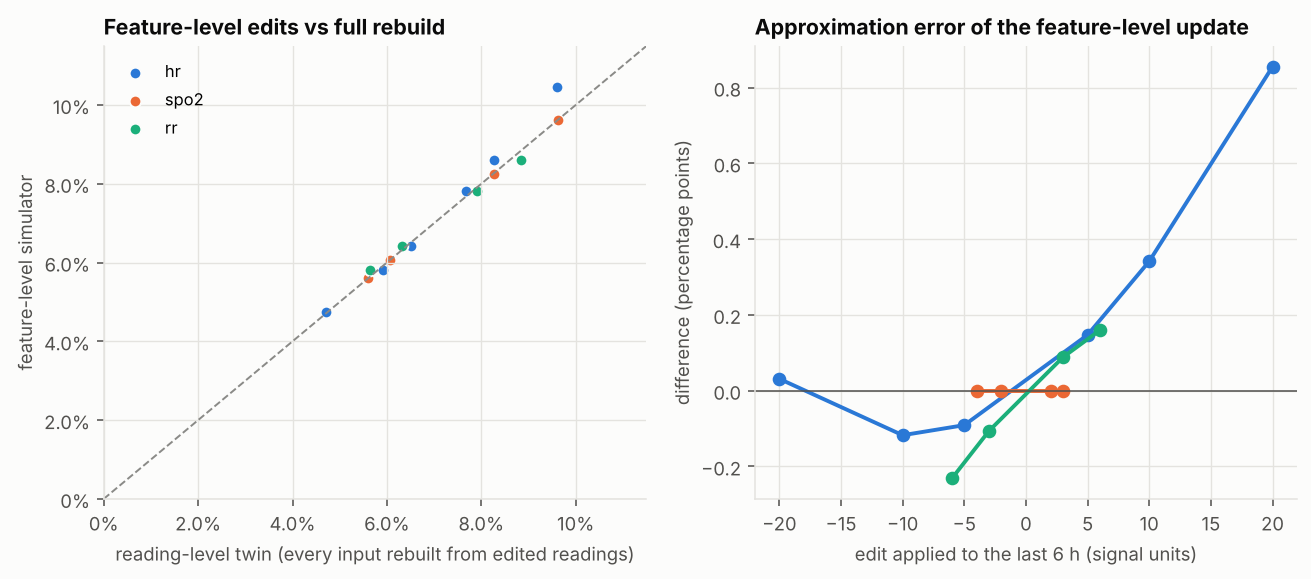

In [14]:
rows = []
for sig, lever, changes in (("hr", "heart_rate", [-20, -10, -5, 5, 10, 20]), ("spo2", "spo2", [-4, -2, 2, 3]),
                            ("rr", "resp_rate", [-6, -3, 3, 6])):
    for d in changes:
        rd = sim.reading_scenario(syn, [{"signal": sig, "delta": d, "hours": 6}])
        ft = sim.simulate(syn, Scenario.of("f", **{lever: {"delta": d}})).outcomes["watch"]
        rows.append({"signal": sig, "change": d, "reading_prob": rd["scenario"]["prob"], "feature_prob": ft.scenario["prob"]})
cons = pd.DataFrame(rows)
cons["abs_error_pts"] = 100 * (cons.feature_prob - cons.reading_prob).abs()
cons.to_csv(RES / "feature_vs_reading_consistency.csv", index=False)
print(f"feature-level vs full rebuild: mean |error| {cons.abs_error_pts.mean():.2f} points, max {cons.abs_error_pts.max():.2f} points "
      f"over {len(cons)} edits (the difference comes from held inputs such as the 24 h SD)")
show(viz.plot_consistency(cons), "11_feature_vs_reading_consistency")

**Result:** the feature-level edits used for the test patients agree with the full rebuild from raw readings to within 0.15 percentage
points on average (largest 0.86 points, for a 20 bpm rise, where the held 24-hour heart-rate SD matters most). Tiers agree in every case
checked.

## 13 · The full risk engine's own what-if (when available)

Notebook 07's `risk_engine.whatif.simulate` re-runs the whole engine (validation, emergency rules, freshness gate, policy, SAR) in
simulation mode. It needs the complete project folder (including `twin_rules.py` and the cleaned replay data). Where it is not
available, the simulator says so instead of imitating it.

In [15]:
res_engine = sim.engine_whatif(syn.request, {"hr": 85})
if res_engine.get("status") == "UNAVAILABLE":
    print(res_engine["reason"])
else:
    print(json.dumps({k: res_engine[k] for k in ("status", "original", "simulated", "difference") if k in res_engine}, indent=1, default=str))
    save_json(res_engine, PAY / "engine_whatif_synthetic.json")

The full risk engine needs twin_rules.py (emergency symptom rules), which is not in this folder. The simulator's own reading-level twin is used instead.


## 14 · Guardrails

Requests that would produce a misleading answer are refused with a reason, never silently "simulated".

In [16]:
G = [Scenario.of("Sleep 8 hours", sleep_duration=8), Scenario.of("Steps 10,000", steps=10000),
     Scenario.of("Heart rate 300", heart_rate={"value": 300}), Scenario.of("Weight and BMI together", weight={"delta": -5}, bmi=22),
     Scenario.of("Diastolic above systolic", clinic_sbp=90, clinic_dbp=95), Scenario.of("HDL without total cholesterol", hdl=60),
     Scenario.of("SpO2 +10 (would exceed 100%)", spo2={"delta": 10})]
rows = []
for s in G:
    c = sim.patients.get("stay-37093652") if "HDL" in s.name else case
    r = sim.simulate(c, s)
    rows.append({"request": s.name, "status": r.status,
                 "reason / note": "; ".join(x["reason"] for x in r.applied.rejected) or "; ".join(r.applied.notes)})
guard = pd.DataFrame(rows)
guard.to_csv(RES / "guardrails.csv", index=False)
display(guard)
try:
    simulate_request(sim, {"case_id": CASE_ID, "scenario": {"name": "x", "changes": {"heart_rate": {"delta": -5}}}}, role="patient")
except PermissionDenied as e:
    print("role check:", e)

,request,status,reason / note
0,Sleep 8 hours,REJECTED,"Sleep: no sleep data existed in training (MIMIC-IV ICU stays), so neither mo..."
1,"Steps 10,000",REJECTED,Steps / physical activity: no activity data in training; no model input.
2,Heart rate 300,REJECTED,Heart rate 300 is outside the accepted range 20-250 bpm.
3,Weight and BMI together,REJECTED,These levers describe the same quantity; change one.
4,Diastolic above systolic,REJECTED,Diastolic BP must be below systolic BP.
5,HDL without total cholesterol,REJECTED,"HDL only enters the models through total cholesterol, which is missing for t..."
6,SpO2 +10 (would exceed 100%),REJECTED,Oxygen saturation 101 is outside the accepted range 50-100 %.


role check: Role 'patient' may not run what-if simulations.


## 15 · The same scenarios across every test patient

Each dot is one held-out test patient, starting from their own baseline. It shows how personal the response is: the same
change moves some patients across a tier cut-off and barely moves others.

,patients,median_delta,min_delta,max_delta,tier_changed
scenario,,,,,
Heart rate -10 bpm,19,-0.77%,-2.18%,-0.36%,5
SpO2 +2 points,17,-0.62%,-1.74%,-0.29%,3
Breathing rate -4 /min,19,+0.61%,+0.29%,+1.66%,2
Stops smoking,19,+0.00%,-2.71%,+0.00%,4
Weight -5 kg,19,+0.16%,+0.09%,+0.61%,0


'Stops smoking' only applies to current smokers; for non-smokers the scenario changes nothing.


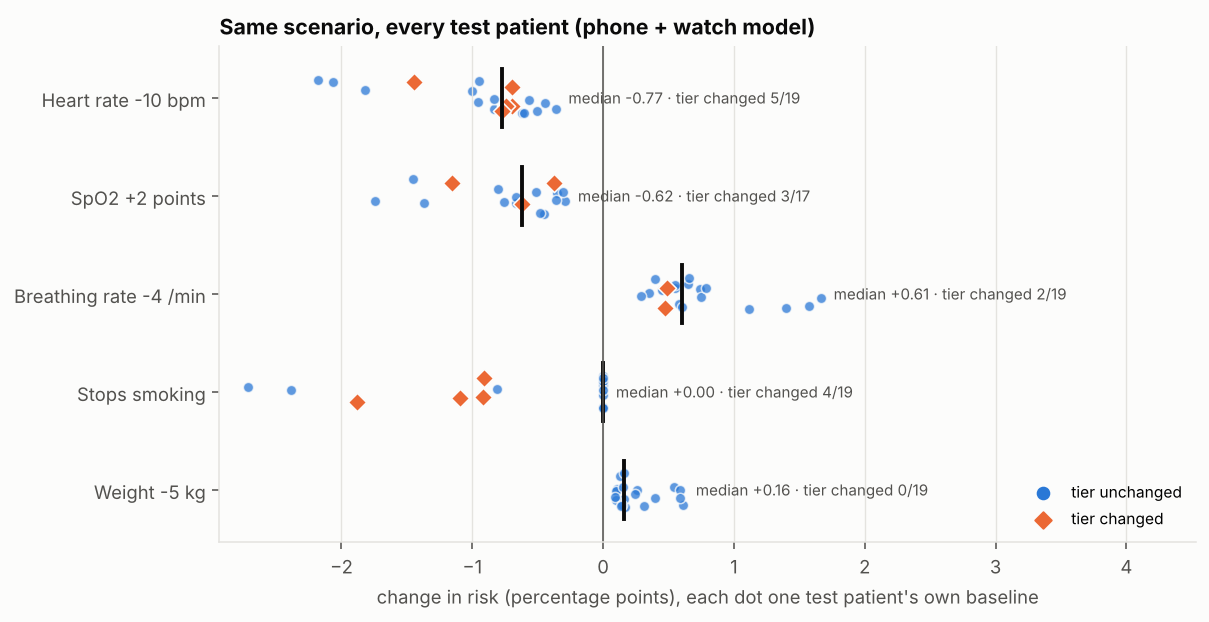

In [17]:
POP = [Scenario.of("Heart rate -10 bpm", heart_rate={"delta": -10}), Scenario.of("SpO2 +2 points", spo2={"delta": 2}),
       Scenario.of("Breathing rate -4 /min", resp_rate={"delta": -4}), Scenario.of("Stops smoking", smoker=0),
       Scenario.of("Weight -5 kg", weight={"delta": -5})]
pop = sim.population(POP, "watch")
pop.to_csv(RES / "population_scenarios.csv", index=False)
summary = pop[pop.status != "REJECTED"].groupby("scenario", sort=False).agg(
    patients=("case_id", "count"), median_delta=("delta", "median"), min_delta=("delta", "min"), max_delta=("delta", "max"),
    tier_changed=("scenario_tier", lambda s: int((s != pop.loc[s.index, "baseline_tier"]).sum())))
display(summary.style.format({"median_delta": "{:+.2%}", "min_delta": "{:+.2%}", "max_delta": "{:+.2%}"}))
print("'Stops smoking' only applies to current smokers; for non-smokers the scenario changes nothing.")
show(viz.plot_population(pop), "12_population")

**Result:** the same edit has very different effects on different patients. Heart rate 10 bpm lower moves the risk between about -0.3
and -2.2 points and changes the tier for 5 of 19 patients; 5 kg less weight never changes a tier. Lowering the breathing rate raises
the watch model's risk for every patient, the clearest example of a learned direction that should not be taken at face value.

## 16 · Interactive simulator

Pick a patient, move one or more sliders, choose whether vital-sign edits apply to the last 6 hours or the whole history, press
**Run**, then **Add to comparison** to build a scenario table. (Needs `ipywidgets`; in a static view the sections above show the same.)

In [18]:
from whatif_twin.widgets import build_panel
panel = build_panel(sim, default_case=CASE_ID)

## 17 · Dashboard integration

`whatif_twin.export.simulate_request(sim, request, role)` is a JSON-in / JSON-out function a backend or the phone app's doctor mode
can call; only roles with the `what_if` permission in `risk_policy.yaml` (clinician) may run it. The response is versioned
(`schema_version`) and always carries the hypothetical label, `simulation: true` and `writes_to_patient_record: false`.

In [19]:
request = {"case_id": CASE_ID, "scenario": {"name": "Vitals in usual range",
           "changes": {"heart_rate": {"value": 100}, "spo2": {"value": 95}, "resp_rate": {"value": 20}}}}
payload = simulate_request(sim, request, role="clinician")
save_json(request, PAY / "example_request.json")
save_json(payload, PAY / "example_response.json")
print(json.dumps({k: payload[k] for k in ("schema_version", "status", "simulation", "writes_to_patient_record", "label")}, indent=1))
print(json.dumps(payload["models"]["watch"]["difference"]), "|", json.dumps(payload["models"]["watch"]["uncertainty"]["verdict"]))
display(pd.DataFrame([{"field": k, "meaning": v} for k, v in PAYLOAD_FIELDS.items()]))

{
 "schema_version": "whatif-payload-1.0",
 "status": "OK",
 "simulation": true,
 "writes_to_patient_record": false,
 "label": "HYPOTHETICAL MODEL SIMULATION. It shows how this model's output responds to edited inputs. It does not change the patient's record, does not predict the effect of any treatment and is not medical advice."
}
{"absolute": -0.01464, "relative": -0.1414, "tier_change": "unchanged"} | "within model variance (direction not stable)"


,field,meaning
0,schema_version,payload format version
1,label,the hypothetical-simulation label the app must show with every result
2,status,OK | NO_MEANINGFUL_CHANGE (all |change| < 0.1 points) | REJECTED (see 'rejec...
3,patient,"case id, label, data source, synthetic flag, hour, models that can score it"
4,scenario / edits,"the requested changes, and every model input that changed (original -> simul..."
5,held_constant,inputs that depend on an edited signal but cannot be recomputed from one hour
6,models.<m>.baseline / scenario / difference,"probability, LOW / MODERATE / HIGH tier and change"
7,models.<m>.uncertainty,"bootstrap-refit spread of baseline, scenario and change; share of refits agr..."
8,models.<m>.explanation,"SHAP group and feature changes (attributions, not causes)"
9,models.<m>.out_of_distribution,edited inputs outside the training range (extrapolation)


## 18 · Automated tests

In [20]:
r = subprocess.run([sys.executable, "-m", "pytest", str(HERE / "tests"), "-q", "-p", "no:cacheprovider", "--color=no",
                    f"--junitxml={RES / 'test_results.xml'}"], capture_output=True, text=True, cwd=HERE)
print(r.stdout[-1500:])

........................                                                 [100%]
24 passed in 8.22s



## 19 · Run summary and reproducibility

In [21]:
summary = {
    "created_with": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                     "scikit-learn": __import__("sklearn").__version__, "lightgbm": __import__("lightgbm").__version__,
                     "shap": __import__("shap").__version__, "whatif_twin": whatif_twin.__version__},
    "model_version": sim.art.manifest["model_version"], "model_sha256": sim.art.hashes, "integrity": sim.art.integrity,
    "policy_version": sim.art.cfg["policy_version"], "selected_case": CASE_ID,
    "baseline": {m: {"prob": round(b["prob"], 4), "tier": b["tier"]} for m, b in base.items()},
    "scenarios": cmp.assign(delta=cmp.delta.round(4))[["scenario", "model", "delta", "tier_change", "robustness"]].to_dict("records"),
    "feature_vs_reading_mean_abs_error_pts": round(float(cons.abs_error_pts.mean()), 3),
    "outputs": sorted(str(p.relative_to(HERE.parent)) for p in list(CH.glob("*.png")) + list(RES.rglob("*.*"))),
    "label": whatif_twin.LABEL,
}
save_json(summary, RES / "whatif_summary.json")
print(f"{len(summary['outputs'])} output files written under {HERE.name}/charts and {HERE.name}/results")

34 output files written under what_if_simulator/charts and what_if_simulator/results


## Limitations

* **Hypothetical, associational and model-specific.** A simulated change shows how *this model* responds. It is not a causal or
  treatment effect: lowering a heart rate on screen says nothing about what lowering it in a patient would do.
* **Small training set.** 59 ICU patients (MIMIC-IV demo). The bootstrap refits show large model variance; several learned
  directions (for example breathing rate, weight) go against usual clinical expectation and are flagged rather than hidden.
* **Target and population.** The target is ICU deterioration (vasopressor start, lactate >= 4 mmol/L or death) within 24 hours.
  Lifestyle levers act on a 24-hour ICU outcome only through what the model learned, not through their long-term effects.
* **Feature-level edits.** For the test patients only one hour of inputs is available here, so a few inputs that depend on the
  whole history (24 h SD, night/day breathing difference, NEWS2 minimum) are held or approximated. Section 12b measures the error
  against a full rebuild. On the full project folder, `sim.patients.at_hour(stay_id, hour)` opens any test hour.
* **Not available as inputs**: sleep, activity, stress, watch HRV, cuffless BP, diet. The simulator refuses them.
* **Thresholds** are provisional cut-offs chosen on cross-validation; nothing here has had clinical review.